# Who Gets Left Out? Predicting and Profiling Financial Exclusion in New York City

## Feature Engineering

### Library Import

This cell imports the Python libraries used throughout the analysis\. Pandas and NumPy are used for cleaning and analyzing tabular data\. GeoPandas is used to work with geographic points and PUMA boundary polygons\. Requests is used to download the Census boundary file, and CSV is used to correctly parse the Census batch\-geocoding results\.

In [1]:
import pandas as pd
import numpy as np
import geopandas as gpd
import requests
import csv
import os
from pathlib import Path
import matplotlib.pyplot as plt
import io
import re
import time
import zipfile

### Load the Neighborhood Financial Health data

In [2]:
# Load Neighborhood Financial Health Digital Mapping and Data Tool
# https://catalog.data.gov/dataset/neighborhood-financial-health-digital-mapping-and-data-tool?from_hint=eyJrZXl3b3JkIjoiZmluYW5jaWFsIGhlYWx0aCJ9

filepath = "../data/"
neighborhood = filepath + "neighborhood_financial_health.csv"
neighborhood_df = pd.read_csv(neighborhood)
print(neighborhood_df.shape)

(385, 52)


This cell loads the Neighborhood Financial Health Digital Mapping and Data Tool from a local CSV file into a pandas DataFrame named neighborhood\_df\. The dataset contains socioeconomic and financial\-health measures for New York City Public Use Microdata Areas \(PUMAs\), including poverty, income, demographic characteristics, financial services, housing stability, access to goods and services, employment, and asset\-building opportunities\. Each PUMA appears in multiple rows because the dataset organizes its indicators into different financial\-health goals and also includes summary categories\. The shape command displays the number of rows and columns in the dataset\.

### Load the FDIC Bank Locations data

In [3]:
# Load FDIC Bank Locations
# https://catalog.data.gov/dataset/fdic-bank-locations?from_hint=eyJxIjoiYmFuayIsInNvcnQiOiJyZWxldmFuY2UifQ%3D%3D

banks = filepath + "locations.csv"
banks_df = pd.read_csv(banks)
print(banks_df.shape)

(78075, 30)
/tmp/ipykernel_126/2019673958.py:5: DtypeWarning: Columns (29: ZIP) have mixed types. Specify dtype option on import or set low_memory=False.
  banks_df = pd.read_csv(banks)


This cell loads the national FDIC Bank Locations dataset from a local CSV file into a pandas DataFrame named banks\_df\. Each row represents an FDIC\-insured bank location and includes information such as the branch address, city, county, state, ZIP code, institution name, and branch name\. 

The dataset also contains UNINUM, which identifies individual bank locations, and CERT, which identifies banking institutions\. These fields will later be used to calculate the number of physical branches and the number of unique banks in each PUMA\.

The shape output displays the number of rows and columns in the dataset\. Because this file includes bank locations throughout the United States, it will next be filtered to New York City’s five counties\.

### Filter and clean the NYC bank data

In [4]:
# Filter for NYC banks and clean up
nyc_banks_df = banks_df[banks_df["STALP"] == "NY"].copy()
nyc_banks_df["ZIP"] = nyc_banks_df["ZIP"].astype(str).str.zfill(5)
#nyc_banks_df["ZIP"] = nyc_banks_df["ZIP"].astype(int)
print(nyc_banks_df.shape)

(4005, 30)


This cell creates a copy of the FDIC data containing only records where the state abbreviation \(STALP\) is NY\. It also standardizes ZIP codes as five\-character text values so that leading zeros are preserved\. ZIP codes should not be converted to integers because they are geographic identifiers rather than quantities\. At this stage, the data include locations across New York State, not only New York City\. The next step will use county names to retain only locations in NYC’s five boroughs\. The shape output displays the number of records and columns remaining after the initial state filter

### Examine the county values

In [5]:
print(nyc_banks_df["COUNTY"].unique())

<ArrowStringArray>
[       'Bronx',       'Queens',       'Nassau',  'Schenectady',
        'Kings',      'Genesee',       'Albany',       'Warren',
     'New York',       'Seneca',       'Oneida',       'Orange',
         'Erie',    'Jefferson',     'Onondaga',  'Westchester',
   'Chautauqua',       'Oswego',      'Suffolk',     'Rockland',
     'Dutchess',     'Columbia',      'Chemung',       'Ulster',
       'Monroe',     'Richmond',        'Lewis',      'Madison',
  'Cattaraugus',       'Broome',     'Tompkins',     'Saratoga',
     'Herkimer',       'Greene',       'Putnam',      'Niagara',
      'Wyoming',        'Yates',        'Wayne',      'Clinton',
     'Sullivan',       'Otsego',   'Washington',      'Ontario',
   'Rensselaer',     'Delaware',     'Allegany',        'Essex',
 'St. Lawrence',   'Livingston',        'Tioga',     'Cortland',
    'Schoharie',      'Steuben',   'Montgomery',     'Franklin',
       'Fulton',       'Cayuga',      'Orleans',     'Chenango',
     '

This cell displays all unique county names found in the New York bank\-location data\. Reviewing these values helps confirm that filtering by STALP = "NY" includes bank locations throughout New York State, not only New York City\. The county field will be used in the next step to identify the five counties corresponding to New York City’s boroughs: Bronx, Kings, New York, Queens, and Richmond\.

### Examine the borough values

In [6]:
print(neighborhood_df["Borough"].unique())


<ArrowStringArray>
['Bronx', 'Manhattan', 'Brooklyn', 'Queens', 'Staten Island']
Length: 5, dtype: str


This cell displays the unique borough names in the Neighborhood Financial Health dataset\. Reviewing these values confirms how New York City’s five boroughs are labeled in the file and helps ensure that the geographic names are consistent with the borough labels that will be created for the FDIC bank data\. The expected values are Bronx, Brooklyn, Manhattan, Queens, and Staten Island\. However, the datasets will ultimately be joined using PUMA codes rather than borough names because PUMAs provide a more detailed geographic unit\.

### Map NYC counties to boroughs

In [7]:
# Mapping of NYC counties to boroughs
nyc_county_to_borough = {
    "Bronx": "Bronx",
    "Kings": "Brooklyn",
    "New York": "Manhattan",
    "Queens": "Queens",
    "Richmond": "Staten Island",
}

# Add a new column 'Borough' to the NYC banks dataframe
nyc_banks_df["Borough"] = nyc_banks_df["COUNTY"].map(nyc_county_to_borough)

# Drop banks outside of NYC counties from the dataset
nyc_banks_df = nyc_banks_df.dropna(subset=["Borough"])
nyc_banks_df.shape

(1404, 31)

New York City’s five boroughs correspond to five counties, but the FDIC dataset identifies locations by county rather than by borough\. This cell maps Bronx County to the Bronx, Kings County to Brooklyn, New York County to Manhattan, Queens County to Queens, and Richmond County to Staten Island\. Counties outside New York City do not receive a borough value and are removed from the dataset\. The resulting nyc\_banks\_df contains only bank locations in New York City, and the shape output reports the number of remaining rows and columns\.

### Confirm the remaining counties

In [8]:
print(nyc_banks_df["COUNTY"].unique())

<ArrowStringArray>
['Bronx', 'Queens', 'Kings', 'New York', 'Richmond']
Length: 5, dtype: str


This cell displays the unique county names remaining after the county\-to\-borough mapping and filtering process\. The output should contain only Bronx, Kings, New York, Queens, and Richmond counties, confirming that locations outside New York City were successfully removed\. These county names correspond to the five boroughs: the Bronx, Brooklyn, Manhattan, Queens, and Staten Island\.

### Preview the cleaned NYC bank data

In [9]:
nyc_banks_df.head()

,ADDRESS,BKCLASS,CBSA,CBSA_DIV,CBSA_DIV_FLG,CBSA_DIV_NO,CBSA_METRO,CBSA_METRO_FLG,CBSA_METRO_NAME,CBSA_MICRO_FLG,...,OFFNAME,OFFNUM,RUNDATE,SERVTYPE,STALP,STCNTY,STNAME,UNINUM,ZIP,Borough
15,1864 Williamsbridge Rd,N,"New York-Newark-Jersey City, NY-NJ-PA","New York-Jersey City-White Plains, NY-NJ",1,35614.0,35620,1,"New York-Newark-Jersey City, NY-NJ-PA",0,...,MORRIS PARK BRANCH,1156,09/04/2026,11,NY,36005,New York,466457,10461,Bronx
39,3902 Main St,N,"New York-Newark-Jersey City, NY-NJ-PA","New York-Jersey City-White Plains, NY-NJ",1,35614.0,35620,1,"New York-Newark-Jersey City, NY-NJ-PA",0,...,FLUSHING BRANCH,9,09/04/2026,11,NY,36081,New York,466470,11354,Queens
63,515 Ocean Ave,N,"New York-Newark-Jersey City, NY-NJ-PA","New York-Jersey City-White Plains, NY-NJ",1,35614.0,35620,1,"New York-Newark-Jersey City, NY-NJ-PA",0,...,CHURCH AND OCEAN AVENUE BRANCH,8920,09/04/2026,11,NY,36047,New York,465882,11226,Brooklyn
218,1023 Avenue Of The Americas,NM,"New York-Newark-Jersey City, NY-NJ-PA","New York-Jersey City-White Plains, NY-NJ",1,35614.0,35620,1,"New York-Newark-Jersey City, NY-NJ-PA",0,...,AVENUE OF THE AMERICAS BRANCH,7,09/04/2026,11,NY,36061,New York,517265,10018,Manhattan
253,9525 Queens Blvd,N,"New York-Newark-Jersey City, NY-NJ-PA","New York-Jersey City-White Plains, NY-NJ",1,35614.0,35620,1,"New York-Newark-Jersey City, NY-NJ-PA",0,...,REGO PARK BRANCH,1305,09/04/2026,11,NY,36081,New York,506527,11374,Queens


This cell displays the first five rows of the cleaned FDIC bank dataset\. The preview helps verify that the filtering and county\-to\-borough mapping were completed correctly\. Each row should represent a bank location in one of New York City’s five boroughs, and the new Borough column should correspond to the value in COUNTY\. The preview also allows us to inspect important fields such as the branch address, city, ZIP code, institution name, UNINUM, and CERT before preparing the addresses for geocoding\.

### Inspect the cleaned NYC bank dataset

In [10]:
nyc_banks_df.info()

<class 'pandas.DataFrame'>
Index: 1404 entries, 15 to 78049
Data columns (total 31 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ADDRESS          1404 non-null   str    
 1   BKCLASS          1404 non-null   str    
 2   CBSA             1404 non-null   str    
 3   CBSA_DIV         1404 non-null   str    
 4   CBSA_DIV_FLG     1404 non-null   int64  
 5   CBSA_DIV_NO      1404 non-null   float64
 6   CBSA_METRO       1404 non-null   int64  
 7   CBSA_METRO_FLG   1404 non-null   int64  
 8   CBSA_METRO_NAME  1404 non-null   str    
 9   CBSA_MICRO_FLG   1404 non-null   int64  
 10  CBSA_NO          1404 non-null   int64  
 11  CERT             1404 non-null   int64  
 12  CITY             1404 non-null   str    
 13  COUNTY           1404 non-null   str    
 14  CSA              1404 non-null   str    
 15  CSA_FLG          1404 non-null   int64  
 16  CSA_NO           1404 non-null   float64
 17  ESTYMD           1404 non-nu

This cell summarizes the structure of the cleaned NYC bank dataset\. The output reports the number of rows, column names, non\-missing values per column, and each column’s data type\. This review helps identify missing values and formatting issues before geocoding the branch addresses\. In particular, it confirms whether key variables—such as UNINUM, CERT, ADDRESS, CITY, COUNTY, ZIP, and Borough—are present and sufficiently complete for the next stages of the analysis\.

### Count bank branches by borough

In [11]:
print("NYC branch count by borough:")
branch_counts = nyc_banks_df.groupby("Borough").size().reset_index(name="Branch_Count")
display(branch_counts)

NYC branch count by borough:


,Borough,Branch_Count
0,Bronx,126
1,Brooklyn,330
2,Manhattan,512
3,Queens,347
4,Staten Island,89


This cell groups the cleaned FDIC records by borough and counts the number of bank\-location records in each group\. The result provides a simple overview of how physical bank branches are distributed across the five boroughs\. At this stage, these are raw branch counts and do not account for differences in population or geographic size\. The later analysis will assign branches to PUMAs, which provide a more detailed geographic level than boroughs\. This calculation assumes that each row represents a unique branch\. If duplicate locations have not already been removed, the branch count should instead use unique UNINUM values:

### Inspect the Neighborhood Financial Health dataset

In [12]:
neighborhood_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 385 entries, 0 to 384
Data columns (total 52 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Year Published    385 non-null    int64  
 1   PUMA              385 non-null    int64  
 2   Borough           385 non-null    str    
 3   Neighborhoods     385 non-null    str    
 4   CD                385 non-null    str    
 5   Join              385 non-null    int64  
 6   NYC_Poverty_Rate  385 non-null    float64
 7   Median_Income     385 non-null    str    
 8   Perc_White        385 non-null    float64
 9   Perc_Black        385 non-null    float64
 10  Perc_Asian        385 non-null    float64
 11  Perc_Other        385 non-null    float64
 12  Perc_Hispanic     385 non-null    float64
 13  Goal              385 non-null    str    
 14  GoalName          385 non-null    str    
 15  GoalFullName      385 non-null    str    
 16  TotalOutcome      367 non-null    float64
 17  GoalRank

This cell summarizes the structure of the Neighborhood Financial Health dataset after standardizing its PUMA identifiers\. The output shows the total number of rows and columns, each column’s name and data type, and the number of nonmissing values in each field\. This review helps verify that important fields—including PUMA, Borough, Neighborhoods, Goal, TotalOutcome, and the indicator variables—are available for analysis\. It also helps identify missing values and variables that may require conversion from text to numeric format before calculations are performed\. Because each PUMA has separate records for different financial\-health goals, the number of rows is expected to be greater than the number of unique PUMAs\.

In [13]:
# This function converts ratio values in the "Ind1Outcome" column into numeric values for Financial Services goal

def convert_ratio_to_decimal(val):
  if pd.isna(val):
    return np.nan

  if isinstance(val, (int, float, np.number)):
    return float(val)

  val = str(val).strip()

# Text ratio like '0.8:1' -> bank & credit unions / nonbanks
  if ":" in val:
    try:
      bank_and_cu, non_bank = (
        float(part) for part in val.split(":")[:2]
      )
    except ValueError:
      return np.nan
    return bank_and_cu / non_bank if non_bank != 0 else np.nan

  try:
    return float(val)
  except ValueError:
    return np.nan


# Keep the original values in Ind1Outcome_raw
if "Ind1Outcome_raw" not in neighborhood_df.columns:
  neighborhood_df = neighborhood_df.rename(columns={"Ind1Outcome": "Ind1Outcome_raw"})

# Other goals keep their original numeric values. Financial Services gets the cleaned decimal.
financial_services_mask = neighborhood_df["Goal"].eq("Financial Services")
neighborhood_df["Ind1Outcome"] = pd.to_numeric(neighborhood_df["Ind1Outcome_raw"], errors="coerce")
neighborhood_df.loc[financial_services_mask, "Ind1Outcome"] = (
  neighborhood_df.loc[financial_services_mask, "Ind1Outcome_raw"]
  .apply(convert_ratio_to_decimal)
)

display(neighborhood_df.loc[financial_services_mask,["Ind1Outcome_raw", "Ind1Outcome"]])


,Ind1Outcome_raw,Ind1Outcome
1,0.125694444,0.125694
9,0.8:1,0.800000
16,2.3:1,2.300000
24,1.7:1,1.700000
32,0.5:1,0.500000
40,0.6:1,0.600000
45,0.3:1,0.300000
53,0.7:1,0.700000
60,0.6:1,0.600000
68,0.5:1,0.500000


In [14]:
# Drop the raw Ind1Outcome column now that the cleaned decimal values are in Ind1Outcome
neighborhood_df = neighborhood_df.drop(columns=["Ind1Outcome_raw"], errors="ignore")
print("Ind1Outcome_raw" in neighborhood_df.columns)

False


In [15]:
#neighborhood_df.head()

### Examine the financial health goal categories

In [16]:
print(neighborhood_df["Goal"].unique())

<ArrowStringArray>
[           'Build Assets',      'Financial Services',
        'Financial Shocks',        'Goods & Services',
           'Jobs & Income',           'Overall Index',
 'Majority Race/Ethnicity']
Length: 7, dtype: str


This cell displays all unique values in the Goal column\. It is used to confirm how the Neighborhood Financial Health dataset categorizes its records and to verify the exact spelling of each category before filtering\. The dataset should include five substantive goals—Build Assets, Financial Services, Financial Shocks, Goods & Services, and Jobs & Income—along with the summary categories Majority Race/Ethnicity and Overall Index\. Reviewing these values helps ensure that the earlier filtering step removed only the intended summary categories\.

### Count financial health goal records by borough

In [17]:
print("Distinct Goals")
neighborhood_df.groupby(["Borough", "GoalFullName"]).size().reset_index(name="Goal_Count")

Distinct Goals


,Borough,GoalFullName,Goal_Count
0,Bronx,"Goal 1: Access to Affordable, High-Quality Fin...",10
1,Bronx,"Goal 2: Access to Affordable, High-Quality Goo...",10
2,Bronx,Goal 3: Access to Quality Jobs & Income Supports,10
3,Bronx,Goal 4: Stable Housing & Capacity to Limit Fin...,10
4,Bronx,Goal 5: Opportunities to Build Assets & Plan f...,10
5,Bronx,Majority Race or Ethnicity,10
6,Bronx,Overall Neighborhood Financial Health,10
7,Brooklyn,"Goal 1: Access to Affordable, High-Quality Fin...",18
8,Brooklyn,"Goal 2: Access to Affordable, High-Quality Goo...",18
9,Brooklyn,Goal 3: Access to Quality Jobs & Income Supports,18


This cell groups the Neighborhood Financial Health data by Borough and GoalFullName, then counts the number of records in each combination\. The results help confirm how many PUMA\-level observations are available for each financial\-health goal within each borough\. Because each row generally represents a PUMA and goal combination, Goal\_Count usually reflects the number of PUMAs represented for that goal in the borough\. Differences in counts may indicate missing records, summary categories, or data\-quality issues that should be reviewed before analysis\.

### Remove summary categories from the financial health data

In [18]:
cleaned_neighborhood_df = neighborhood_df[
    ~neighborhood_df["Goal"].isin([
        "Majority Race/Ethnicity",
        "Overall Index"
    ])
].copy()

display(cleaned_neighborhood_df)

,Year Published,PUMA,Borough,Neighborhoods,CD,Join,NYC_Poverty_Rate,Median_Income,Perc_White,Perc_Black,...,Ind6Definition,Ind7,Ind7Outcome,Ind7Rank,Ind7Definition,Ind8,Ind8Outcome,Ind8Rank,Ind8Definition,Ind1Outcome
0,2020,3701,Bronx,"Riverdale, Fieldston & Kingsbridge",BX Community District 8,3701,0.152,"30,437",0.324,0.124,...,Percentage of jobs in small businesses (less t...,Participatory Budgeting,0.071777,26.0,Percentage of eligible residents casting a vot...,NaN,NaN,NaN,NaN,0.316000
1,2020,3701,Bronx,"Riverdale, Fieldston & Kingsbridge",BX Community District 8,3701,0.152,"30,437",0.324,0.124,...,Percentage of bank & credit union branches off...,Mobile Banking Utilization,0.205800,23.0,Estimated percentage of residents that used mo...,NaN,NaN,NaN,NaN,0.125694
2,2020,3701,Bronx,"Riverdale, Fieldston & Kingsbridge",BX Community District 8,3701,0.152,"30,437",0.324,0.124,...,Number of pre-foreclosure notices issued per 1...,Financial Counseling,0.000000,40.0,Full-Time Equivalent Financial Counselors per ...,NaN,NaN,NaN,NaN,0.640000
3,2020,3701,Bronx,"Riverdale, Fieldston & Kingsbridge",BX Community District 8,3701,0.152,"30,437",0.324,0.124,...,Average (mean) travel time to work in minutes,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,206.270000
4,2020,3701,Bronx,"Riverdale, Fieldston & Kingsbridge",BX Community District 8,3701,0.152,"30,437",0.324,0.124,...,Percentage of people eligible for SNAP receivi...,Tax Credit Utilization,0.966000,9.0,Percentage of eligible Tax Units claiming EITC,Adults With High School Diploma,0.845032,21.0,Percentage of adults with a high school degree...,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
378,2020,4114,Queens,"Far Rockaway, Breezy Point & Broad Channel",QN Community District 14,4114,0.179,"25,920",0.350,0.353,...,Percentage of jobs in small businesses (less t...,Participatory Budgeting,0.185821,6.0,Percentage of eligible residents casting a vot...,NaN,NaN,NaN,NaN,0.367000
379,2020,4114,Queens,"Far Rockaway, Breezy Point & Broad Channel",QN Community District 14,4114,0.179,"25,920",0.350,0.353,...,Percentage of bank & credit union branches off...,Mobile Banking Utilization,0.178600,35.0,Estimated percentage of residents that used mo...,NaN,NaN,NaN,NaN,0.125694
380,2020,4114,Queens,"Far Rockaway, Breezy Point & Broad Channel",QN Community District 14,4114,0.179,"25,920",0.350,0.353,...,Number of pre-foreclosure notices issued per 1...,Financial Counseling,1.413969,21.0,Full-Time Equivalent Financial Counselors per ...,NaN,NaN,NaN,NaN,0.430000
381,2020,4114,Queens,"Far Rockaway, Breezy Point & Broad Channel",QN Community District 14,4114,0.179,"25,920",0.350,0.353,...,Average (mean) travel time to work in minutes,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,193.800000


This cell removes the Majority Race/Ethnicity and Overall Index rows from the Neighborhood Financial Health dataset\. These rows summarize neighborhood demographics or overall financial health rather than representing one of the five individual financial\-health goals\. The cleaned dataset retains the goal categories for financial services, goods and services, jobs and income, financial shocks, and asset building\. Each PUMA still appears multiple times because it has a separate row for each goal\. The display\(\) function shows the resulting DataFrame so the remaining records and variables can be reviewed\.

### Clean and validate the PUMA identifiers

In [19]:
def clean_puma(series):
    return (
        series.astype("string")
        .str.strip()
        .str.replace(r"\.0$", "", regex=True)
        .str.zfill(4)
    )

neighborhood_df["PUMA"] = clean_puma(neighborhood_df["PUMA"])

# The Join field should generally match PUMA
if "Join" in neighborhood_df.columns:
    neighborhood_df["Join"] = clean_puma(neighborhood_df["Join"])

    mismatches = neighborhood_df.loc[
        neighborhood_df["PUMA"].notna()
        & neighborhood_df["Join"].notna()
        & neighborhood_df["PUMA"].ne(neighborhood_df["Join"]),
        ["PUMA", "Join"]
    ]

    print("PUMA/Join mismatches:", len(mismatches))

print("Unique NFH PUMAs:", neighborhood_df["PUMA"].nunique())

PUMA/Join mismatches: 0
Unique NFH PUMAs: 55


This cell standardizes the Public Use Microdata Area \(PUMA\) codes so they can be used as reliable geographic join keys\. The clean\_puma\(\) function converts each value to text, removes extra spaces, removes a possible \.0 suffix created when identifiers are read as numbers, and formats each code as four characters\.

The same cleaning process is applied to the Join column because the data dictionary describes it as a duplicate PUMA field created for the original mapping tool\. The code then compares PUMA and Join and counts any rows in which both fields are present but do not agree\. Ideally, the mismatch count should be zero\.

Finally, the cell reports the number of unique PUMAs in the Neighborhood Financial Health dataset\. Because each PUMA appears in multiple goal rows, this count is smaller than the total number of rows\.

### Prepare bank addresses for geocoding

In [20]:
# Keep ZIP as a five-character string
nyc_banks_df["ZIP"] = (
    nyc_banks_df["ZIP"]
    .astype("string")
    .str.replace(r"\.0$", "", regex=True)
    .str.extract(r"(\d{5})", expand=False)
    .str.zfill(5)
)

nyc_banks_df["full_address"] = (
    nyc_banks_df["ADDRESS"].fillna("").astype(str).str.strip()
    + ", "
    + nyc_banks_df["CITY"].fillna("").astype(str).str.strip()
    + ", NY "
    + nyc_banks_df["ZIP"].fillna("")
)

print(nyc_banks_df["full_address"].head())

15             1864 Williamsbridge Rd, Bronx, NY 10461
39                    3902 Main St, Flushing, NY 11354
63                   515 Ocean Ave, Brooklyn, NY 11226
218    1023 Avenue Of The Americas, New York, NY 10018
253              9525 Queens Blvd, Rego Park, NY 11374
Name: full_address, dtype: str


This cell prepares the NYC bank\-location records for geocoding\. First, it standardizes ZIP codes as five\-character text values\. Keeping ZIP codes as strings preserves leading zeros and avoids treating them as quantities\. The code also removes decimal suffixes that may have been added when the CSV was imported and extracts the first five digits if a longer ZIP code is present\.

Next, the street address, city, state abbreviation, and ZIP code are combined into a new column called full\_address\. For example, the resulting value may look like 515 Ocean Ave, Brooklyn, NY 11226\. These complete addresses can be submitted to a geocoding service to obtain latitude and longitude coordinates for each bank branch\. The final line displays the first five complete addresses so their formatting can be checked\.

### Create the Census batch geocoding input file

In [21]:
batch_input_df = (
    nyc_banks_df[
        ["UNINUM", "ADDRESS", "CITY", "STALP", "ZIP"]
    ]
    .drop_duplicates(subset=["UNINUM"])
    .copy()
)

batch_input_df["ZIP"] = (
    batch_input_df["ZIP"]
    .astype("string")
    .str.replace(r"\.0$", "", regex=True)
    .str.extract(r"(\d{5})", expand=False)
    .str.zfill(5)
)

# Required order: ID, street, city, state, ZIP
batch_input_df.to_csv(
    filepath + "census_batch_input.csv",
    index=False,
    header=False
)

print(batch_input_df.shape)
#batch_input_df.head()

(1404, 5)


This cell prepares the NYC bank records for the U\.S\. Census Batch Geocoder\. It selects the five fields required by the geocoder: the unique location identifier \(UNINUM\), street address, city, state abbreviation, and ZIP code\. Duplicate UNINUM values are removed so that each bank location is submitted only once\. The ZIP codes are again standardized as five\-character strings to preserve leading zeros and remove any decimal suffixes introduced during import\. 

The records are saved as census\_batch\_input\.csv in the exact column order required by the Census Geocoder\. The file is written without column headers or row numbers because the batch service expects only the raw records\. The final line reports the number of bank locations and fields included in the upload file\. This file is then uploaded to the U\.S\. Census Batch Geocoder, and the downloaded results are saved as GeocodeResults\.csv\.

### Parse the Census geocoding results

In [22]:
# Parse the Census batch-geocoding results

records = []

with open(
    filepath + "GeocodeResults.csv",
    newline="",
    encoding="utf-8-sig"
) as file:
    reader = csv.reader(file)

    for row in reader:
        record = {
            "UNINUM": row[0].strip(),
            "input_address": row[1].strip(),
            "match_status": row[2].strip(),
            "match_type": pd.NA,
            "matched_address": pd.NA,
            "longitude": np.nan,
            "latitude": np.nan,
            "tigerline_id": pd.NA,
            "side": pd.NA,
            "state_fips": pd.NA,
            "county_fips": pd.NA,
            "tract": pd.NA,
            "block": pd.NA
        }

        if len(row) == 12 and row[2].strip() == "Match":
            longitude, latitude = row[5].split(",")

            record.update({
                "match_type": row[3].strip(),
                "matched_address": row[4].strip(),
                "longitude": float(longitude),
                "latitude": float(latitude),
                "tigerline_id": row[6].strip(),
                "side": row[7].strip(),
                "state_fips": row[8].strip(),
                "county_fips": row[9].strip(),
                "tract": row[10].strip(),
                "block": row[11].strip()
            })

        records.append(record)

batch_results_df = pd.DataFrame(records)

print(batch_results_df.shape)
print(batch_results_df["match_status"].value_counts(dropna=False))


(1404, 13)
match_status
Match       1365
No_Match      27
Tie           12
Name: count, dtype: int64


This cell reads the GeocodeResults\.csv file downloaded from the U\.S\. Census Batch Geocoder and converts it into a pandas DataFrame\. The csv library is used because address fields contain commas and must be interpreted according to the file’s quotation rules\.

For every submitted bank location, the code records its FDIC location identifier \(UNINUM\), original input address, and geocoding status\. Records marked Match include additional information: the type of match, the standardized address returned by the Census Geocoder, longitude, latitude, TIGER/Line identifier, and street side\. The coordinate field is separated into longitude and latitude so that it can later be converted into a geographic point\.

Records marked Tie or No\_Match are still retained, but their geographic fields remain missing because the geocoder did not identify one definite location\. Finally, all parsed records are stored in batch\_results\_df for review and merging with the original FDIC data\.

### Review the geocoding results

In [23]:
print(batch_results_df.shape)

print(
    batch_results_df["match_status"]
    .value_counts(dropna=False)
)

print(
    batch_results_df[
        [
            "UNINUM",
            "match_status",
            "matched_address",
            "longitude",
            "latitude"
        ]
    ].head()
)

(1404, 13)
match_status
Match       1365
No_Match      27
Tie           12
Name: count, dtype: int64
   UNINUM match_status                             matched_address  longitude  \
0  214112          Tie                                         NaN        NaN   
1  452087        Match          1350 BROADWAY, NEW YORK, NY, 10018 -73.987579   
2  236385        Match  900 HUGUENOT AVE, STATEN ISLAND, NY, 10312 -74.191986   
3  182677        Match           2218 5TH AVE, NEW YORK, NY, 10037 -73.937738   
4  236382        Match    475 FOREST AVE, STATEN ISLAND, NY, 10301 -74.105178   

    latitude  
0        NaN  
1  40.751355  
2  40.532202  
3  40.812726  
4  40.630696  


This cell checks the results returned by the U\.S\. Census Batch Geocoder\. First, it displays the number of rows and columns in batch\_results\_df\. Next, it counts the records in each match\_status category\. A Match indicates that the geocoder identified one location and returned coordinates, while a Tie means that multiple possible locations were found and no single result was selected\. Finally, the cell displays a sample of the results, including the FDIC location identifier, match status, standardized matched address, longitude, and latitude\. This review confirms how many branches can be included in the geographic analysis and identifies records that may require additional cleaning or manual review\.

### Validate the geocoded coordinates

In [24]:
batch_results_df["valid_nyc_coordinate"] = (
    batch_results_df["longitude"].between(-74.30, -73.65)
    & batch_results_df["latitude"].between(40.45, 40.95)
)

print(
    batch_results_df["valid_nyc_coordinate"]
    .value_counts(dropna=False)
)

valid_nyc_coordinate
True     1365
False      39
Name: count, dtype: int64


This cell performs a basic quality check on the coordinates returned by the Census Geocoder\. It creates a Boolean field called valid\_nyc\_coordinate, which is True when the longitude and latitude fall within an approximate bounding box surrounding New York City and False otherwise\. The selected range is broad enough to include all five boroughs while helping identify coordinates that were matched to locations far outside the study area\.

The value counts show how many records have plausible NYC coordinates and how many require review\. Records without coordinates, including addresses marked Tie or No\_Match, are also classified as False\. This bounding\-box check is only an initial validation step; the later spatial join to the official PUMA boundaries provides a more precise geographic check\.

### Review coordinates outside the approximate NYC boundary

In [25]:
outside_nyc_df = batch_results_df[
    batch_results_df["longitude"].notna()
    & ~batch_results_df["valid_nyc_coordinate"]
]

print(outside_nyc_df.shape)

print(
    outside_nyc_df[
        [
            "UNINUM",
            "input_address",
            "matched_address",
            "longitude",
            "latitude"
        ]
    ].head(20)
)

(0, 14)
Empty DataFrame
Columns: [UNINUM, input_address, matched_address, longitude, latitude]
Index: []


This cell identifies records that received coordinates from the Census Geocoder but fall outside the approximate New York City bounding box defined in the previous step\. It excludes records with missing longitude values because those locations were not successfully geocoded and therefore cannot be evaluated spatially\.

The output displays the number of potentially incorrect geographic matches and previews up to 20 records, including the submitted address, the standardized address returned by the geocoder, and the resulting coordinates\. Comparing the input and matched addresses helps determine whether a branch was assigned to the wrong place\. These records should be reviewed before they are excluded or included in the spatial analysis\. A point outside the approximate bounding box is not automatically incorrect, but it is a useful signal that the geocoding result may need further investigation\.

### Standardize and validate the bank location identifier

In [26]:
nyc_banks_df["UNINUM"] = (
    nyc_banks_df["UNINUM"]
    .astype("string")
    .str.strip()
)

batch_results_df["UNINUM"] = (
    batch_results_df["UNINUM"]
    .astype("string")
    .str.strip()
)

print(
    "Duplicate Census IDs:",
    batch_results_df["UNINUM"].duplicated().sum()
)

Duplicate Census IDs: 0


This cell prepares the UNINUM field for joining the FDIC bank records with the Census geocoding results\. UNINUM is the FDIC identifier for an individual bank location\. The code converts it to a string in both DataFrames and removes any extra spaces\. Both tables must use the same data type and formatting for the merge to work correctly\.

The final line checks whether any UNINUM values appear more than once in the Census results\. Ideally, the duplicate count should be zero because each branch was submitted to the geocoder once and should have one result\. Duplicate identifiers should be investigated before using a one\-to\-one merge, since they could cause a branch to be repeated in the joined data\.

### Review addresses with tied geocoding results

In [27]:
tied_addresses_df = batch_results_df[
    batch_results_df["match_status"].eq("Tie")
].copy()

print(tied_addresses_df.shape)

print(
    tied_addresses_df[
        ["UNINUM", "input_address"]
    ].head(39)
)

(12, 14)
      UNINUM                                  input_address
0     214112         250 Broadway, New York City, NY, 10007
80    442299              3654 Main St, Flushing, NY, 11354
118   214138           1 Park Ave, New York City, NY, 10016
133   596941              230 Park Ave, New York, NY, 10169
247    47765                1 Park Ave, New York, NY, 10016
320    47731              277 Park Ave, New York, NY, 10017
577   447236                2 Park Ave, New York, NY, 10016
676   682075            3720 Prince St, Flushing, NY, 11354
703   534152     2131 46th Ave, Long Island City, NY, 11101
932   521686  1030 Jackson Ave, Long Island City, NY, 11101
1007  532144              247 Avenue U, Brooklyn, NY, 11223
1038  361739              3630 Main St, Flushing, NY, 11354


This cell identifies bank addresses marked as Tie by the U\.S\. Census Geocoder\. A tied result means that the geocoder found multiple equally plausible locations and could not select one definitive match\. As a result, these records do not have reliable longitude and latitude values and cannot yet be assigned to a PUMA\.

The output reports the number of tied records and displays their FDIC location identifiers and submitted addresses for review\. These addresses can be corrected and resubmitted if needed, but they should not be automatically assigned to a PUMA\. The analysis can continue using successfully matched branches, while the excluded tied records should be documented as a limitation\. Using \.head\(39\) displays up to 39 records; display\(tied\_addresses\_df\[\["UNINUM", "input\_address"\]\]\) can be used to show all tied records regardless of their number\.

### Create the Census tract identifier

In [28]:
required_fields = [
    "state_fips",
    "county_fips",
    "tract"
]

complete_geography = (
    batch_results_df[required_fields]
    .notna()
    .all(axis=1)
)

batch_results_df["TRACT_GEOID"] = pd.NA

batch_results_df.loc[
    complete_geography,
    "TRACT_GEOID"
] = (
    batch_results_df.loc[
        complete_geography,
        "state_fips"
    ].astype("string").str.zfill(2)
    + batch_results_df.loc[
        complete_geography,
        "county_fips"
    ].astype("string").str.zfill(3)
    + batch_results_df.loc[
        complete_geography,
        "tract"
    ].astype("string").str.zfill(6)
)

This cell creates an 11\-character Census tract Geographic Identifier \(TRACT\_GEOID\) for each successfully geocoded bank location\. The identifier combines the two\-digit state Federal Information Processing Standards code, the three\-digit county code, and the six\-digit census tract code\. For example, a New York County tract may be represented as 36061010900\.

Standardizing each component with leading zeros ensures that every tract identifier has the correct length and can be used consistently for geographic validation or for joining to tract\-level reference files\. Records that were tied or unmatched will have missing tract identifiers because the Census Geocoder did not return complete geography information\.

The primary project join still assigns branches to PUMA polygons using longitude and latitude\. TRACT\_GEOID is an additional geographic reference and is not the final key used to join the FDIC data to the Neighborhood Financial Health dataset\.

### Download the PUMA boundary file

In [29]:
url = (
    "https://www2.census.gov/geo/tiger/TIGER2019/"
    "PUMA/tl_2019_36_puma10.zip"
)

response = requests.get(url, timeout=60)
response.raise_for_status()

with open(filepath + "tl_2019_36_puma10.zip", "wb") as file:
    file.write(response.content)

print("Download complete")

Download complete


This cell downloads the U\.S\. Census Bureau’s Public Use Microdata Area boundary file for New York State\. The file comes from the 2019 TIGER/Line release, but puma10 in the filename indicates that it contains the 2010 PUMA boundaries\. We need these boundaries because the Neighborhood Financial Health dataset uses the older PUMA geography and four\-digit NYC PUMA codes\.

The requests\.get\(\) function retrieves the ZIP archive from the Census website\. The 60\-second timeout prevents the request from waiting indefinitely, while raise\_for\_status\(\) produces an error if the download fails\. The response is then saved locally as tl\_2019\_36\_puma10\.zip\. GeoPandas can read the shapefile directly from this ZIP archive, so it does not need to be manually extracted\.

The boundary file includes all PUMAs in New York State\. A later step will retain only the PUMAs that appear in the Neighborhood Financial Health dataset\.

### Load and inspect the PUMA boundaries

In [30]:
pumas_gdf = gpd.read_file(
    "zip://" + filepath + "tl_2019_36_puma10.zip"
)

print(pumas_gdf.shape)
print(pumas_gdf.columns.tolist())
pumas_gdf.head()

(145, 11)
['STATEFP10', 'PUMACE10', 'GEOID10', 'NAMELSAD10', 'MTFCC10', 'FUNCSTAT10', 'ALAND10', 'AWATER10', 'INTPTLAT10', 'INTPTLON10', 'geometry']


,STATEFP10,PUMACE10,GEOID10,NAMELSAD10,MTFCC10,FUNCSTAT10,ALAND10,AWATER10,INTPTLAT10,INTPTLON10,geometry
0,36,03803,3603803,NYC-Manhattan Community District 10--Central H...,G6120,S,3703013,241237,+40.8137240,-073.9429990,"POLYGON ((-73.95151 40.81201, -73.95093 40.812..."
1,36,03707,3603707,NYC-Bronx Community District 5--Morris Heights...,G6120,S,3911383,24513,+40.8528801,-073.9087693,"POLYGON ((-73.90981 40.85735, -73.90777 40.859..."
2,36,03201,3603201,Nassau County (Northwest)--North Hempstead Tow...,G6120,S,99602738,40461994,+40.8170441,-073.6919814,"POLYGON ((-73.6281 40.81604, -73.62778 40.8160..."
3,36,03301,3603301,Suffolk County (Northwest)--Huntington Town (N...,G6120,S,117162753,39052772,+40.8985365,-073.3956826,"POLYGON ((-73.36815 40.86364, -73.36726 40.863..."
4,36,03303,3603303,Suffolk County (Northwest)--Smithtown Town PUMA,G6120,S,139212989,18726758,+40.8704498,-073.2169705,"POLYGON ((-73.23268 40.91328, -73.15192 40.938..."


This cell uses GeoPandas to load the New York State 2010 PUMA boundary shapefile directly from the downloaded ZIP archive\. The zip:// prefix tells GeoPandas to read the geographic files inside the archive without requiring manual extraction\.

The resulting GeoDataFrame, pumas\_gdf, contains one row for each PUMA polygon in New York State\. The shape output reports the number of geographic features and columns, while the column list helps identify important fields such as the PUMA code and polygon geometry\. The first five rows are displayed to confirm that the file loaded successfully\.

At this stage, the file contains PUMAs throughout New York State\. The next steps will standardize the PUMA codes, retain only those used by the Neighborhood Financial Health dataset, and match the polygon coordinate system to the bank point layer\.

### Standardize the PUMA codes

In [31]:
pumas_gdf["PUMA"] = (
    pumas_gdf["PUMACE10"]
    .astype("string")
    .str.strip()
    .str.zfill(5)
    .str[-4:]
)

print(pumas_gdf[["PUMACE10", "PUMA"]].head())

  PUMACE10  PUMA
0    03803  3803
1    03707  3707
2    03201  3201
3    03301  3301
4    03303  3303


This cell reformats the Census PUMA identifiers so they match the codes used in the Neighborhood Financial Health dataset\. The boundary file stores New York PUMA codes as five\-character values, such as 03701, while the financial\-health data use four\-character codes, such as 3701\.

The code converts PUMACE10 to text, removes extra spaces, pads the value to five characters, and retains the final four characters\. The new standardized identifier is stored in a column named PUMA\. The output displays the original and reformatted codes side by side to verify the conversion before joining the datasets\.

### Merge the geocoding results with the NYC bank data

In [32]:
# Standardize the branch identifier in both dataframes
nyc_banks_df["UNINUM"] = (
    nyc_banks_df["UNINUM"]
    .astype("string")
    .str.strip()
)

batch_results_df["UNINUM"] = (
    batch_results_df["UNINUM"]
    .astype("string")
    .str.strip()
)

# Confirm that the geocoding results contain one row per branch ID
print(
    "Duplicate Census IDs:",
    batch_results_df["UNINUM"].duplicated().sum()
)

# Merge the geocoding results into the original NYC bank records
nyc_banks_geocoded_df = nyc_banks_df.merge(
    batch_results_df[
        [
            "UNINUM",
            "match_status",
            "match_type",
            "matched_address",
            "longitude",
            "latitude",
            "valid_nyc_coordinate"
        ]
    ],
    on="UNINUM",
    how="left",
    validate="one_to_one"
)

print("Geocoded NYC bank data shape:", nyc_banks_geocoded_df.shape)

print(
    "Banks with valid NYC coordinates:",
    nyc_banks_geocoded_df["valid_nyc_coordinate"]
    .fillna(False)
    .sum()
)

nyc_banks_geocoded_df[
    [
        "UNINUM",
        "ADDRESS",
        "CITY",
        "ZIP",
        "match_status",
        "longitude",
        "latitude",
        "valid_nyc_coordinate"
    ]
].head()

nyc_banks_geocoded_df.to_csv(
    filepath + "nyc_banks_geocoded.csv",
    index=False
)

Duplicate Census IDs: 0
Geocoded NYC bank data shape: (1404, 38)
Banks with valid NYC coordinates: 1365


This cell combines the original NYC bank\-location data with the results returned by the U\.S\. Census Batch Geocoder\. The two datasets are connected using UNINUM, the FDIC identifier for an individual bank location\. Before performing the merge, UNINUM is converted to text and stripped of extra spaces in both DataFrames to ensure that matching identifiers have the same format\.

The duplicate check verifies that each bank identifier appears no more than once in the Census results\. Ideally, this count should be zero\. Duplicate identifiers could create repeated bank records and incorrectly increase the branch counts calculated later\.

The left join preserves every branch in nyc\_banks\_df, including addresses that were tied or not matched by the Census Geocoder\. Successfully matched records receive a match status, match type, standardized address, longitude, latitude, and an indicator showing whether the coordinates fall within the approximate New York City boundary\. The validate="one\_to\_one" argument provides an additional quality check by requiring each branch identifier to occur no more than once in each dataset\.

The resulting DataFrame, nyc\_banks\_geocoded\_df, contains both the original FDIC branch information and the geographic information needed for spatial analysis\. The final output reports the size of the merged dataset and the number of branches with valid NYC coordinates\. Only those valid records will be converted into geographic points and assigned to PUMAs\.

### Convert valid bank coordinates into geographic points

In [33]:
valid_banks_df = nyc_banks_geocoded_df.dropna(
    subset=["longitude", "latitude"]
).copy()

# Retain coordinates within an approximate NYC bounding box
valid_banks_df = valid_banks_df[
    valid_banks_df["longitude"].between(-74.30, -73.65)
    & valid_banks_df["latitude"].between(40.45, 40.95)
].copy()

banks_gdf = gpd.GeoDataFrame(
    valid_banks_df,
    geometry=gpd.points_from_xy(
        valid_banks_df["longitude"],
        valid_banks_df["latitude"]
    ),
    crs="EPSG:4326"
)

print("Geocoded bank points:", banks_gdf.shape)
banks_gdf[
    ["UNINUM", "ADDRESS", "longitude", "latitude", "geometry"]
].head()

Geocoded bank points: (1365, 39)


,UNINUM,ADDRESS,longitude,latitude,geometry
0,466457,1864 Williamsbridge Rd,-73.852290,40.851598,POINT (-73.85229 40.8516)
1,466470,3902 Main St,-73.830498,40.760142,POINT (-73.8305 40.76014)
2,465882,515 Ocean Ave,-73.960964,40.650240,POINT (-73.96096 40.65024)
3,517265,1023 Avenue Of The Americas,-73.985941,40.752442,POINT (-73.98594 40.75244)
4,506527,9525 Queens Blvd,-73.863952,40.730965,POINT (-73.86395 40.73096)


This cell prepares the successfully geocoded bank branches for spatial analysis\. It first removes records without longitude or latitude, including addresses that received a tied or unsuccessful geocoding result\. It then retains only coordinates within an approximate New York City bounding box, helping exclude points that may have been geocoded to an incorrect location outside the study area\.

The remaining coordinates are converted into spatial point geometries and stored in the GeoDataFrame banks\_gdf\. The coordinate reference system is set to WGS 84 \(EPSG:4326\), which is used for longitude and latitude\. Each row now represents a physical bank branch as a geographic point that can be assigned to a PUMA polygon\.

The output reports the number of valid bank points and previews the branch identifier, address, coordinates, and geometry\.

### Validate the bank location point layer

In [34]:
print(type(banks_gdf))
print(banks_gdf.crs)
print(banks_gdf.geometry.notna().sum())

<class 'geopandas.geodataframe.GeoDataFrame'>
EPSG:4326
1365


This cell confirms that the bank location data were converted into a spatial dataset correctly\. The first output verifies that banks\_gdf is a GeoPandas GeoDataFrame rather than a regular pandas DataFrame\. The second displays its coordinate reference system, which should be EPSG:4326, the standard longitude\-and\-latitude coordinate system\. The final output counts the number of records with nonmissing point geometries\. This number should generally match the number of rows in banks\_gdf, confirming that every retained bank record has a valid spatial point that can be used in the PUMA spatial join\.

### Map the geocoded bank locations

<Axes: >

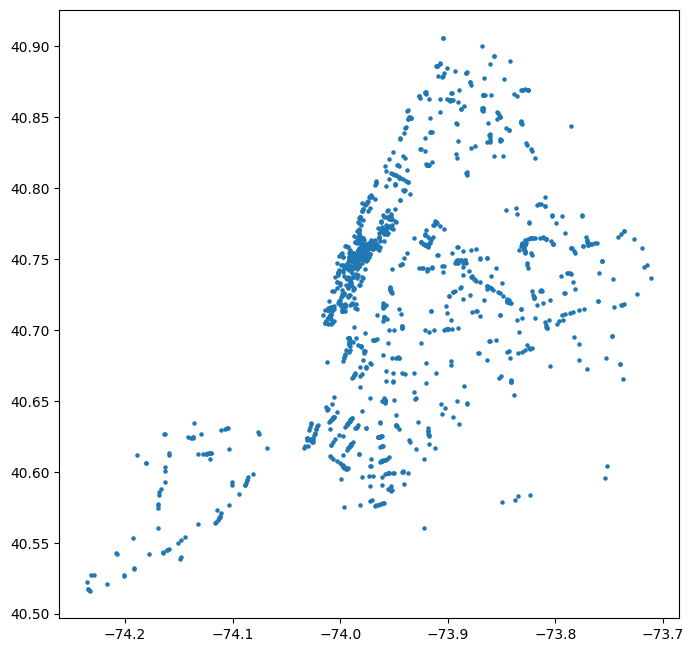

In [35]:
banks_gdf.plot(
    figsize=(8, 8),
    markersize=5
)

This cell creates a basic map of the successfully geocoded bank branches\. Each marker represents one FDIC bank location based on its longitude and latitude\. The map provides a visual quality check before the branches are assigned to PUMAs\. The points should form the general shape of New York City without isolated locations far outside the five boroughs\.

This plot shows only the bank points and does not yet include borough or PUMA boundaries\. Dense clusters are expected in areas with many branches, especially Manhattan\. Any isolated or unusually positioned point may indicate a geocoding error that should be reviewed\.

### Preview the key geocoding fields

In [36]:
batch_results_df[
    ["UNINUM", "match_status", "longitude", "latitude"]
].head()

,UNINUM,match_status,longitude,latitude
0,214112,Tie,NaN,NaN
1,452087,Match,-73.987579,40.751355
2,236385,Match,-74.191986,40.532202
3,182677,Match,-73.937738,40.812726
4,236382,Match,-74.105178,40.630696


This cell displays the first five records from the Census geocoding results, focusing on the fields needed for the spatial analysis\. UNINUM identifies the FDIC bank location, match\_status indicates whether the Census Geocoder found a unique address match, and longitude and latitude identify the branch’s geographic position\.

Successfully matched records should have numeric coordinates\. Records marked Tie or No\_Match will generally have missing coordinate values and are excluded from the bank point layer\. This preview provides a quick check that the geocoding results were parsed correctly\.

### Standardize the PUMA join fields

In [37]:
pumas_gdf["PUMA"] = (
    pumas_gdf["PUMACE10"]
    .astype("string")
    .str.strip()
    .str.zfill(5)
    .str[-4:]
)

neighborhood_df["PUMA"] = clean_puma(
    neighborhood_df["PUMA"]
)

cleaned_neighborhood_df["PUMA"] = clean_puma(
    cleaned_neighborhood_df["PUMA"]
)

This cell ensures that the PUMA identifiers in the Census boundary file and Neighborhood Financial Health dataset use the same format\. The Census boundary file stores New York PUMA codes in the PUMACE10 field as five\-character values, such as 03701, while the Neighborhood Financial Health dataset uses four\-character values, such as 3701\.

For the boundary data, the code converts PUMACE10 to text, removes extra spaces and possible decimal suffixes, pads the value to five characters, and retains the last four characters\. For the financial\-health data, it converts PUMA to text, removes spaces and decimal suffixes, and pads it to four characters\. Standardizing both fields prevents otherwise identical PUMA codes from failing to match because of formatting differences\.

### Filter the PUMA boundaries to the study area

In [38]:
nfh_pumas = set(
    neighborhood_df["PUMA"]
    .dropna()
    .unique()
)

nyc_pumas_gdf = pumas_gdf[
    pumas_gdf["PUMA"].isin(nfh_pumas)
][["PUMA", "geometry"]].copy()

print("NFH PUMAs:", len(nfh_pumas))
print(
    "Matched PUMA polygons:",
    nyc_pumas_gdf["PUMA"].nunique()
)

NFH PUMAs: 55
Matched PUMA polygons: 55


The Census boundary file contains PUMAs throughout New York State, while the Neighborhood Financial Health dataset covers New York City\. This cell creates a set of the PUMA codes found in the financial\-health data and uses it to retain only matching polygons from the Census boundary file\. The resulting nyc\_pumas\_gdf contains only the PUMA code and polygon geometry needed for the spatial join\.

The two printed counts provide a validation check\. NFH PUMAs shows the number of unique PUMA codes in the financial\-health data, while Matched PUMA polygons shows how many of those codes were found in the boundary file\. The counts should be equal—typically 55 for this dataset\. If they differ, the PUMA formats or boundary vintage should be checked before continuing\.

### Match the coordinate reference systems

In [39]:
nyc_pumas_gdf = nyc_pumas_gdf.to_crs(
    banks_gdf.crs
)

print("Bank CRS:", banks_gdf.crs)
print("PUMA CRS:", nyc_pumas_gdf.crs)

Bank CRS: EPSG:4326
PUMA CRS: EPSG:4326


This cell converts the PUMA boundary polygons to the same coordinate reference system \(CRS\) as the bank\-location points\. A CRS defines how geographic coordinates correspond to locations on Earth\. Spatial operations can produce incorrect results if the point and polygon layers use different coordinate systems\.

The bank points use WGS 84 \(EPSG:4326\), the standard coordinate system for longitude and latitude\. The to\_crs\(\) method transforms the PUMA polygons into that same system\. The printed output confirms that both banks\_gdf and nyc\_pumas\_gdf now use the same CRS\. Once the coordinate systems match, the two layers are ready for the spatial join that assigns each bank branch to a PUMA\.

### Assign each bank branch to a PUMA

In [40]:
banks_with_puma_gdf = gpd.sjoin(
    banks_gdf,
    nyc_pumas_gdf,
    how="left",
    predicate="within"
)

banks_with_puma_gdf = banks_with_puma_gdf.drop(
    columns=["index_right"],
    errors="ignore"
)

print(
    "Banks assigned to PUMA:",
    banks_with_puma_gdf["PUMA"].notna().sum(),
    "of",
    len(banks_with_puma_gdf)
)

Banks assigned to PUMA: 1365 of 1365


This cell performs a spatial join between the bank\-location points and the PUMA boundary polygons\. The within predicate assigns a PUMA code to each bank point when the point falls inside a PUMA polygon\. This step creates the geographic link needed to combine the FDIC branch data with the Neighborhood Financial Health data\.

A left spatial join preserves every bank point in banks\_gdf, even if it cannot be assigned to a PUMA\. Successfully assigned branches receive a value in the PUMA column, while unmatched branches retain a missing PUMA value\. GeoPandas also creates an index\_right column showing the matched polygon’s original row index; this temporary field is removed because it is not needed for the analysis\.

The final output reports how many bank branches were successfully assigned to a PUMA out of the total number of valid geocoded bank points\. Ideally, nearly all points should receive a PUMA\. Unmatched points should be reviewed because they may lie near a boundary, have inaccurate coordinates, or fall outside the selected PUMA polygons\.

### Summarize bank access by PUMA

In [41]:
bank_summary_df = (
    banks_with_puma_gdf
    .dropna(subset=["PUMA"])
    .groupby("PUMA", as_index=False)
    .agg(
        FDIC_Branch_Count=("UNINUM", "nunique"),
        Unique_Bank_Count=("CERT", "nunique")
    )
)

print(bank_summary_df.shape)
bank_summary_df.head()

(55, 3)


,PUMA,FDIC_Branch_Count,Unique_Bank_Count
0,3701,14,10
1,3702,7,6
2,3703,19,11
3,3704,23,10
4,3705,7,5



This cell converts the branch\-level spatial data into a PUMA\-level summary\. Bank records that were not assigned to a PUMA are excluded\. The remaining records are grouped by PUMA, producing one row for each represented PUMA\.

FDIC\_Branch\_Count counts distinct physical bank locations using UNINUM, the unique FDIC location identifier\. Unique\_Bank\_Count counts distinct banking institutions using CERT, the FDIC certificate number\. A single institution may operate several branches in the same PUMA, so the branch count is generally greater than or equal to the unique\-bank count\.

For example, if a PUMA contains four branches of one bank and two branches of another, FDIC\_Branch\_Count equals six while Unique\_Bank\_Count equals two\. The output displays the dimensions of the PUMA\-level table and previews its first five rows\. These measures are raw counts and have not yet been adjusted for differences in PUMA population\.

### 

In [42]:
cleaned_neighborhood_df["PUMA"] = clean_puma(
    cleaned_neighborhood_df["PUMA"]
)

### Join the bank summary to the financial health data

In [43]:
combined_df = cleaned_neighborhood_df.merge(
    bank_summary_df,
    on="PUMA",
    how="left",
    validate="many_to_one"
)

This cell combines the cleaned Neighborhood Financial Health data with the PUMA\-level bank summary using the shared PUMA identifier\. A left join keeps every record in cleaned\_neighborhood\_df, even if a matching bank summary is unavailable\. When a match is found, the corresponding FDIC\_Branch\_Count and Unique\_Bank\_Count values are added to the financial\-health record\.

The merge is validated as many\_to\_one because the financial health dataset contains multiple rows for each PUMA, typically one for each financial health goal, while bank\_summary\_df contains one summary row per PUMA\. This validation prevents accidental duplication if the bank summary unexpectedly contains more than one row for a PUMA\.

The resulting combined\_df is the main analytical dataset\. It contains the Neighborhood Financial Health measures together with the number of FDIC\-insured bank branches and distinct banking institutions in each PUMA\. Because each PUMA has multiple financial\-health goal rows, its bank counts are repeated across those rows\.

### Check for PUMAs without bank summary data

In [44]:
print(
    "PUMAs with no bank summary:",
    combined_df.loc[
        combined_df["FDIC_Branch_Count"].isna(),
        "PUMA"
    ].unique()
)

PUMAs with no bank summary: <ArrowStringArray>
[]
Length: 0, dtype: string


This cell identifies PUMAs in the financial health dataset that did not receive an FDIC\_Branch\_Count during the merge\. A missing count can mean that the PUMA contains no matched FDIC bank branches, but it can also indicate a problem with PUMA formatting, geocoding, boundary assignment, or the merge itself\.


The output should therefore be reviewed before replacing missing values with zero\. If the listed PUMA codes are valid, matched geographic areas, and no branches were assigned to them, the missing values may reasonably be treated as zero\. If the PUMAs failed to match because of a processing issue, that issue should be corrected instead\. An empty output indicates that every financial health PUMA received a bank summary\.

### Replace confirmed missing bank counts with zero

In [45]:
combined_df[
    ["FDIC_Branch_Count", "Unique_Bank_Count"]
] = combined_df[
    ["FDIC_Branch_Count", "Unique_Bank_Count"]
].fillna(0).astype(int)

This cell replaces missing values in FDIC\_Branch\_Count and Unique\_Bank\_Count with zero and converts both fields to integers\. This treatment is appropriate only after confirming that the missing values represent PUMAs with no successfully assigned FDIC branches rather than failed joins, incorrect PUMA formatting, or incomplete geocoding\.

After this step, every financial\-health record has numeric bank\-count variables\. A value of zero indicates that no FDIC branch or distinct FDIC\-insured institution was assigned to that PUMA\. Because the financial health dataset contains multiple goal rows for each PUMA, the same PUMA\-level counts appear on each corresponding goal row\.

### Save the final datasets

In [46]:
bank_summary_df.to_csv(
    filepath + "fdic_bank_summary_by_puma.csv",
    index=False
)

combined_df.to_csv(
    filepath + "neighborhood_financial_health_with_banks.csv",
    index=False
)

print("Final shape:", combined_df.shape)

Final shape: (275, 54)


This cell exports the two final datasets as CSV files\. The first file, fdic\_bank\_summary\_by\_puma\.csv, contains one row per PUMA with FDIC\_Branch\_Count, representing the number of distinct physical bank branches, and Unique\_Bank\_Count, representing the number of distinct FDIC\-insured banking institutions\.

The second file, neighborhood\_financial\_health\_with\_banks\.csv, contains the cleaned Neighborhood Financial Health records joined with the PUMA\-level bank measures\. Since the financial health dataset includes multiple goal records for each PUMA, the same bank counts appear on each goal row associated with that PUMA\.

The index=False setting prevents pandas from writing the DataFrame’s row index as an unnecessary column\. The final print statement displays the number of rows and columns in the combined dataset as a final validation check\.

In [47]:
display(bank_summary_df)

,PUMA,FDIC_Branch_Count,Unique_Bank_Count
0,3701,14,10
1,3702,7,6
2,3703,19,11
3,3704,23,10
4,3705,7,5
5,3706,16,9
6,3707,4,2
7,3708,7,5
8,3709,14,9
9,3710,14,11


In [48]:
display(combined_df)

,Year Published,PUMA,Borough,Neighborhoods,CD,Join,NYC_Poverty_Rate,Median_Income,Perc_White,Perc_Black,...,Ind7Outcome,Ind7Rank,Ind7Definition,Ind8,Ind8Outcome,Ind8Rank,Ind8Definition,Ind1Outcome,FDIC_Branch_Count,Unique_Bank_Count
0,2020,3701,Bronx,"Riverdale, Fieldston & Kingsbridge",BX Community District 8,3701,0.152,"30,437",0.324,0.124,...,0.071777,26.0,Percentage of eligible residents casting a vot...,NaN,NaN,NaN,NaN,0.316000,14,10
1,2020,3701,Bronx,"Riverdale, Fieldston & Kingsbridge",BX Community District 8,3701,0.152,"30,437",0.324,0.124,...,0.205800,23.0,Estimated percentage of residents that used mo...,NaN,NaN,NaN,NaN,0.125694,14,10
2,2020,3701,Bronx,"Riverdale, Fieldston & Kingsbridge",BX Community District 8,3701,0.152,"30,437",0.324,0.124,...,0.000000,40.0,Full-Time Equivalent Financial Counselors per ...,NaN,NaN,NaN,NaN,0.640000,14,10
3,2020,3701,Bronx,"Riverdale, Fieldston & Kingsbridge",BX Community District 8,3701,0.152,"30,437",0.324,0.124,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,206.270000,14,10
4,2020,3701,Bronx,"Riverdale, Fieldston & Kingsbridge",BX Community District 8,3701,0.152,"30,437",0.324,0.124,...,0.966000,9.0,Percentage of eligible Tax Units claiming EITC,Adults With High School Diploma,0.845032,21.0,Percentage of adults with a high school degree...,0.000000,14,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
270,2020,4114,Queens,"Far Rockaway, Breezy Point & Broad Channel",QN Community District 14,4114,0.179,"25,920",0.350,0.353,...,0.185821,6.0,Percentage of eligible residents casting a vot...,NaN,NaN,NaN,NaN,0.367000,7,6
271,2020,4114,Queens,"Far Rockaway, Breezy Point & Broad Channel",QN Community District 14,4114,0.179,"25,920",0.350,0.353,...,0.178600,35.0,Estimated percentage of residents that used mo...,NaN,NaN,NaN,NaN,0.125694,7,6
272,2020,4114,Queens,"Far Rockaway, Breezy Point & Broad Channel",QN Community District 14,4114,0.179,"25,920",0.350,0.353,...,1.413969,21.0,Full-Time Equivalent Financial Counselors per ...,NaN,NaN,NaN,NaN,0.430000,7,6
273,2020,4114,Queens,"Far Rockaway, Breezy Point & Broad Channel",QN Community District 14,4114,0.179,"25,920",0.350,0.353,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,193.800000,7,6


### Classify PUMAs using the NFH methodology

In [49]:
# Function to classify NFH tiers per NEIGHBORHOOD FINANCIAL HEALTH (NFH) INDEX: SOURCES AND METHODOLOGY
def classify_nfh_neighborhoods(df):
    if df["ScoreRank"].isna().any():
        raise ValueError("Each PUMA goal must have an NFH score tier")

    puma_tier_counts = df.groupby("PUMA").agg(
        Goal_Count=("Goal", "nunique"),
        Top_Third_Goals=("ScoreRank", lambda ranks: ranks.eq("Top").sum()),
        Bottom_Third_Goals=("ScoreRank", lambda ranks: ranks.eq("Bottom").sum())
    )

    if not puma_tier_counts["Goal_Count"].eq(5).all():
        raise ValueError("Each PUMA must have exactly five NFH goals")

    puma_tier_counts["NFH_Classification"] = np.select(
        [
            puma_tier_counts["Top_Third_Goals"].ge(4),
            puma_tier_counts["Bottom_Third_Goals"].ge(4)
        ],
        [
            "NFH Advantaged neighborhoods",
            "NFH Vulnerable neighborhoods"
        ],
        default="Variable neighborhoods"
    )

    classified_df = df.copy()
    classified_df["NFH_Classification"] = classified_df["PUMA"].map(
        puma_tier_counts["NFH_Classification"]
    )

    return classified_df, puma_tier_counts


This function classifies each PUMA according to the Neighborhood Financial Health methodology\. The NFH framework divides each of the five goal scores into top, middle, and bottom thirds\. A PUMA is classified as NFH Advantaged if it ranks in the top third for at least four of the five goals\. It is classified as NFH Vulnerable if it ranks in the bottom third for at least four goals\. All other PUMAs are classified as Variable\.

Before creating the classifications, the function performs two validation checks\. First, it confirms that every goal record has a value in ScoreRank\. Second, it verifies that every PUMA has exactly five distinct financial\-health goals\. These checks prevent incomplete PUMA records from being classified incorrectly\.

The function then counts the number of top\-third and bottom\-third goal scores for each PUMA and applies the published classification rules\. Finally, it maps the resulting PUMA\-level classification back onto every goal\-level row\. It returns both the complete classified dataset and a PUMA\-level summary table containing the goal count, number of top\-third goals, number of bottom\-third goals, and final NFH classification\.

### Apply the NFH neighborhood classifications

In [50]:
combined_df, puma_tier_counts = classify_nfh_neighborhoods(combined_df)
print(puma_tier_counts["NFH_Classification"].value_counts())

NFH_Classification
Variable neighborhoods          33
NFH Advantaged neighborhoods    12
NFH Vulnerable neighborhoods    10
Name: count, dtype: int64


This cell applies the previously defined classify\_nfh\_neighborhoods\(\) function to the combined financial health and bank dataset\. The function reviews each PUMA’s scores across the five financial health goals and assigns one of three classifications: NFH Advantaged, NFH Vulnerable, or Variable\.

The updated combined\_df contains the new NFH\_Classification column on every goal\-level row\. The puma\_tier\_counts DataFrame contains one row per PUMA and summarizes its total number of goals, number of top\-third goals, number of bottom\-third goals, and final classification\.

The printed output reports the number of PUMAs in each classification\. These counts provide a quality check and summarize the distribution of neighborhood financial health classifications across New York City\. Because each PUMA appears five times in combined\_df, the PUMA\-level puma\_tier\_counts table should be used when counting or comparing classifications\.

### Reshape the financial health data to one row per PUMA

In [51]:
# Function to flatten neighborhood financial health data by PUMA

def flatten_nfh_by_puma(df):
    goal_fields = [
        "GoalName",
        "GoalFullName",
        "TotalOutcome",
        "GoalRank",
        "IndexScore",
        "ScoreRank",
    ]
    for i in range(1, 9):
        goal_fields.extend([
            f"Ind{i}",
            f"Ind{i}Outcome",
            f"Ind{i}Rank",
            f"Ind{i}Definition",
        ])

    shared_fields = [
        column for column in df.columns
        if column not in goal_fields and column != "Goal"
    ]

    if df.duplicated(["PUMA", "Goal"]).any():
        raise ValueError("Expected one row per PUMA and NFHI goal")

    expected_goal_count = df["Goal"].nunique()
    if not df.groupby("PUMA")["Goal"].nunique().eq(expected_goal_count).all():
        raise ValueError("Each PUMA must contain the same set of NFHI goals")

    shared_value_counts = df.groupby("PUMA")[shared_fields].nunique(dropna=False)
    if not shared_value_counts.le(1).all().all():
        raise ValueError("Shared fields must be constant within each PUMA")

    goal_wide_df = (
        df
        .set_index(["PUMA", "Goal"])[goal_fields]
        .unstack("Goal")
    )
    goal_wide_df.columns = [
        f"{goal}__{field}" for field, goal in goal_wide_df.columns
    ]

    puma_fields_df = (
        df[shared_fields]
        .drop_duplicates("PUMA")
        .set_index("PUMA")
    )
    return (
        puma_fields_df
        .join(goal_wide_df, validate="one_to_one")
        .reset_index()
    )


The combined dataset currently contains multiple rows for each PUMA because each row represents one of the five financial health goals\. This function converts the data from this goal\-level format into a wide, PUMA\-level format with exactly one row per PUMA\.

The function separates the columns into two groups\. The first group contains goal\-specific fields, including the goal score, rank, index score, score tier, and up to eight indicators\. These fields are reshaped into separate columns for each goal\. For example, the financial services index score becomes Financial Services\_\_IndexScore, while the financial shocks index score becomes Financial Shocks\_\_IndexScore\.

The second group contains shared PUMA\-level fields, such as borough, neighborhood name, poverty rate, median income, demographic percentages, FDIC branch count, unique\-bank count, and NFH classification\. These values should remain constant across the five goal rows for the same PUMA and are retained only once\.

Before reshaping, the function performs several validation checks\. It confirms that each PUMA has only one row for each goal, that all PUMAs contain the same number of goals, and that the shared fields do not vary within a PUMA\. If any of these assumptions are violated, the function stops and reports an error instead of creating an unreliable output\.

The final result contains one row per PUMA, making it easier to compare financial health goals, bank access, demographics, and neighborhood classifications without counting the same PUMA multiple times\.

### Create and save the final PUMA\-level dataset

In [52]:
flat_combined_df = flatten_nfh_by_puma(combined_df)
flat_combined_df.to_csv(
    filepath + "neighborhood_financial_health_flat_by_puma.csv",
    index=False
)

This cell applies the flatten\_nfh\_by\_puma\(\) function to the combined financial health and bank dataset\. The function converts the data from multiple goal\-level rows per PUMA into a wide format containing exactly one row per PUMA\. Shared neighborhood characteristics, FDIC branch measures, and the NFH classification appear once, while each goal’s scores, ranks, and indicators are stored in separate goal\-specific columns\.

The resulting DataFrame is saved as neighborhood\_financial\_health\_flat\_by\_puma\.csv\. Setting index=False prevents pandas from adding the DataFrame’s row index as an unnecessary output column\. The final checks report the dataset’s dimensions and number of unique PUMAs\. The number of rows should equal the number of unique PUMAs, confirming that the flattening process produced one observation per geographic area\.

### Validate the flattened PUMA\-level dataset

In [53]:
print("Flattened shape:", flat_combined_df.shape)
print("Rows per PUMA:", flat_combined_df["PUMA"].nunique())

Flattened shape: (55, 206)
Rows per PUMA: 55


This cell checks the dimensions of the flattened dataset and counts its unique PUMA identifiers\. Because flat\_combined\_df was designed to contain one row per PUMA, the total number of rows shown in Flattened shape should equal the number of Unique PUMAs\. If these values match, the reshaping process successfully removed the repeated goal\-level rows without losing or duplicating geographic areas\.

The original label Rows per PUMA was changed to Unique PUMAs because the code counts distinct PUMA identifiers rather than the number of rows associated with each PUMA\.

In [54]:
display(flat_combined_df)


,PUMA,Year Published,Borough,Neighborhoods,CD,Join,NYC_Poverty_Rate,Median_Income,Perc_White,Perc_Black,...,Build Assets__Ind8Rank,Financial Services__Ind8Rank,Financial Shocks__Ind8Rank,Goods & Services__Ind8Rank,Jobs & Income__Ind8Rank,Build Assets__Ind8Definition,Financial Services__Ind8Definition,Financial Shocks__Ind8Definition,Goods & Services__Ind8Definition,Jobs & Income__Ind8Definition
0,3701,2020,Bronx,"Riverdale, Fieldston & Kingsbridge",BX Community District 8,3701,0.152,"30,437",0.324,0.124,...,NaN,NaN,NaN,NaN,21.0,NaN,NaN,NaN,NaN,Percentage of adults with a high school degree...
1,3702,2020,Bronx,"Wakefield, Williamsbridge & Woodlawn",BX Community District 12,3702,0.232,"26,136",0.069,0.655,...,NaN,NaN,NaN,NaN,31.0,NaN,NaN,NaN,NaN,Percentage of adults with a high school degree...
2,3703,2020,Bronx,"Coop City, Pelham Bay & Schuylerville",BX Community District 10,3703,0.140,"31,573",0.293,0.285,...,NaN,NaN,NaN,NaN,25.0,NaN,NaN,NaN,NaN,Percentage of adults with a high school degree...
3,3704,2020,Bronx,"Pelham Parkway, Morris Park & Laconia",BX Community District 11,3704,0.205,"25,358",0.218,0.215,...,NaN,NaN,NaN,NaN,38.0,NaN,NaN,NaN,NaN,Percentage of adults with a high school degree...
4,3705,2020,Bronx,"Belmont, Crotona Park East & East Tremont",BX Community Districts 3 & 6,3705,0.308,"14,213",0.045,0.301,...,NaN,NaN,NaN,NaN,51.0,NaN,NaN,NaN,NaN,Percentage of adults with a high school degree...
5,3706,2020,Bronx,"Bedford Park, Fordham North & Norwood",BX Community District 7,3706,0.264,"18,674",0.066,0.154,...,NaN,NaN,NaN,NaN,50.0,NaN,NaN,NaN,NaN,Percentage of adults with a high school degree...
6,3707,2020,Bronx,"Morris Heights, Fordham South & Mount Hope",BX Community District 5,3707,0.344,"15,628",0.013,0.274,...,NaN,NaN,NaN,NaN,53.0,NaN,NaN,NaN,NaN,Percentage of adults with a high school degree...
7,3708,2020,Bronx,"Concourse, Highbridge & Mount Eden",BX Community District 4,3708,0.323,"16,710",0.017,0.308,...,NaN,NaN,NaN,NaN,52.0,NaN,NaN,NaN,NaN,Percentage of adults with a high school degree...
8,3709,2020,Bronx,"Castle Hill, Clason Point & Parkchester",BX Community District 9,3709,0.264,"20,300",0.028,0.288,...,NaN,NaN,NaN,NaN,49.0,NaN,NaN,NaN,NaN,Percentage of adults with a high school degree...
9,3710,2020,Bronx,"Hunts Point, Longwood & Melrose",BX Community Districts 1 & 2,3710,0.293,"15,510",0.016,0.282,...,NaN,NaN,NaN,NaN,55.0,NaN,NaN,NaN,NaN,Percentage of adults with a high school degree...


### Retrieve population estimates for each PUMA

In [55]:
import os
from pathlib import Path

# Source: 2020 ACS 5-year Detailed Table B01003, estimate B01003_001E (total population).
api_key = os.environ.get("CENSUS_API_KEY", "").strip()
local_key_path = Path(filepath + "apikey.txt")

if not api_key and local_key_path.exists():
    api_key = local_key_path.read_text(encoding="utf-8-sig").strip()

if not api_key:
    raise RuntimeError("Set CENSUS_API_KEY or provide a local apikey.txt file to query the Census API.")

census_url = "https://api.census.gov/data/2020/acs/acs5"

try:
    census_response = requests.get(
        census_url,
        params={
            "get": "NAME,B01003_001E",
            "for": "public use microdata area:*",
            "in": "state:36",
            "key": api_key,
        },
        timeout=30,
    )
    census_response.raise_for_status()
except requests.RequestException as exc:
    raise RuntimeError(f"Census ACS request failed: {exc.__class__.__name__}") from None

census_rows = census_response.json()
acs_population_all_ny = pd.DataFrame(census_rows[1:], columns=census_rows[0])
acs_population_all_ny["PUMA"] = (
    acs_population_all_ny["public use microdata area"].astype("string").str[-4:].str.zfill(4)
)
acs_population_all_ny["ACS_Population_2020"] = pd.to_numeric(
    acs_population_all_ny["B01003_001E"], errors="coerce"
)

nfh_puma_ids = (
    pd.read_csv(filepath + "neighborhood_financial_health_flat_by_puma.csv")["PUMA"]
    .astype("string").str.replace(r"\.0$", "", regex=True).str.zfill(4)
)
acs_puma_population_df = acs_population_all_ny.loc[
    acs_population_all_ny["PUMA"].isin(set(nfh_puma_ids)),
    ["PUMA", "NAME", "ACS_Population_2020"],
].rename(columns={"NAME": "ACS_PUMA_Name_2020"}).copy()

if acs_puma_population_df["PUMA"].duplicated().any():
    raise ValueError("ACS returned duplicate PUMA population records.")
if set(acs_puma_population_df["PUMA"]) != set(nfh_puma_ids):
    raise ValueError("ACS PUMAs do not exactly match the 55 PUMAs in the prepared NFH dataset.")
if acs_puma_population_df["ACS_Population_2020"].isna().any() or acs_puma_population_df["ACS_Population_2020"].le(0).any():
    raise ValueError("ACS population estimates must be present and positive for every PUMA.")

acs_puma_population_df.to_csv(filepath + "acs_puma_population_2020.csv", index=False)
print(f"Matched ACS population estimates to {len(acs_puma_population_df)} NFH PUMAs.")
print("Source: 2020 ACS 5-year, B01003_001E; geography: 2010 PUMA vintage.")
display(acs_puma_population_df.head())


Matched ACS population estimates to 55 NFH PUMAs.
Source: 2020 ACS 5-year, B01003_001E; geography: 2010 PUMA vintage.


,PUMA,ACS_PUMA_Name_2020,ACS_Population_2020
0,4003,NYC-Brooklyn Community District 3--Bedford-Stu...,151080
1,4010,NYC-Brooklyn Community District 17--East Flatb...,133144
2,4002,NYC-Brooklyn Community District 4--Bushwick PU...,128411
3,3805,NYC-Manhattan Community District 8--Upper East...,214450
4,3809,NYC-Manhattan Community District 3--Chinatown ...,155356


This cell retrieves total population estimates for New York State PUMAs from the U\.S\. Census Bureau’s 2020 American Community Survey \(ACS\) five\-year API\. It requests variable B01003\_001E, which is the estimated total population from Detailed Table B01003\. The population denominator will later be used to convert raw FDIC branch counts into branches per 10,000 residents\.

The code first looks for a Census API key in the CENSUS\_API\_KEY environment variable\. If the environment variable is unavailable, it checks for a local apikey\.txt file\. The API key should not be printed, displayed, or included in a shared notebook or repository\. The request then retrieves the PUMA name, population estimate, state code, and PUMA code for all PUMAs in New York State\.

The API response is converted into a pandas DataFrame\. The Census PUMA identifiers are reformatted to match the four\-character codes in the Neighborhood Financial Health data, and the population estimates are converted to numeric values\. The code then reads the PUMAs in the prepared one\-row\-per\-PUMA NFH file and keeps only matching Census records\.

Several checks ensure that the population data are suitable for the analysis\. Each PUMA must appear once, the set of ACS PUMAs must exactly match the PUMAs in the prepared NFH file, and every population estimate must be present and greater than zero\. The validated results are saved as acs\_puma\_population\_2020\.csv\.

### Add ACS population estimates to the PUMA\-level dataset

In [56]:
### Add validated ACS population estimates to the flattened PUMA-level dataframe.

# Ensure PUMA codes are properly formatted and validated before merging population data.
flat_combined_df["PUMA"] = (
    flat_combined_df["PUMA"]
    .astype("string")
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(4)
)
acs_puma_population_df["PUMA"] = (
    acs_puma_population_df["PUMA"]
    .astype("string")
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(4)
)

# Check for duplicate PUMA codes in both dataframes.
if flat_combined_df["PUMA"].duplicated().any():
    raise ValueError("flat_combined_df must contain exactly one row per PUMA.")
if acs_puma_population_df["PUMA"].duplicated().any():
    raise ValueError("ACS population data contains duplicate PUMA identifiers.")

# Check for unmatched PUMAs before merging population data.
population_lookup = acs_puma_population_df.set_index("PUMA")["ACS_Population_2020"]
unmatched_pumas = flat_combined_df.loc[
    ~flat_combined_df["PUMA"].isin(population_lookup.index), "PUMA"
].tolist()
if unmatched_pumas:
    raise ValueError(f"ACS population is missing for these PUMAs: {unmatched_pumas}")

# Merge the ACS population data into the flattened PUMA-level dataframe.
flat_combined_df["ACS_Population_2020"] = flat_combined_df["PUMA"].map(population_lookup)
if flat_combined_df["ACS_Population_2020"].isna().any() or flat_combined_df["ACS_Population_2020"].le(0).any():
    raise ValueError("ACS_Population_2020 must be present and positive for every PUMA.")

# Review the merged dataset.
print("PUMAs with population:", flat_combined_df["ACS_Population_2020"].notna().sum())
display(flat_combined_df[["PUMA", "ACS_Population_2020"]].head())


PUMAs with population: 55


,PUMA,ACS_Population_2020
0,3701,108015
1,3702,151909
2,3703,122076
3,3704,125749
4,3705,168574


This cell adds the validated 2020 American Community Survey population estimate to each row of the flattened Neighborhood Financial Health dataset\. Because flat\_combined\_df contains one row per PUMA, the population value can be added directly using the shared PUMA identifier\.

The code first standardizes the PUMA fields in both datasets as four\-character text values\. It then verifies that neither dataset contains duplicate PUMA codes, since both tables should have exactly one row per geographic area\. Next, it creates a lookup that maps each PUMA to its 2020 ACS population estimate and checks whether any PUMAs in the financial\-health data are absent from the population table\.

The population values are added to flat\_combined\_df using the PUMA lookup\. A final validation confirms that every PUMA has a nonmissing and positive population estimate\. The output reports the number of PUMAs with population data and displays a sample of the matched values\.

This population field will serve as the denominator for calculating FDIC bank branches and unique banking institutions per 10,000 residents\. Because the population estimate is from the 2020 ACS five\-year release, any normalized measures should be clearly labeled as using the 2020 population denominator\.

### Load Federally Insured Credit Union Data

In [57]:
# Load the federally insured credit union data.
# Source data: https://ncua.gov/analysis/credit-union-corporate-call-report-data
# Click on "List of Active Federally Insured Credit Unions"
# The downloaded file is as of 2026 Q2.

credit_union_dir = Path.cwd().parent
candidate_paths = [
    credit_union_dir / "data" / "FederallyInsuredCreditUnions_2026q2.xlsx",
]
credit_union_path = next((p for p in candidate_paths if p.exists()), None)

if credit_union_path is None:
    raise FileNotFoundError("Could not find FederallyInsuredCreditUnions_2026q2.xlsx in the working directory.")

credit_union_df = pd.read_excel(credit_union_path, sheet_name="FICUs")
print(f"Loaded {credit_union_path.name}: {credit_union_df.shape[0]} rows x {credit_union_df.shape[1]} columns")
credit_union_df.head()


Loaded FederallyInsuredCreditUnions_2026q2.xlsx: 4214 rows x 23 columns


,Charter number,Year and quarter,Credit Union name,Street \n(Mailing address),City \n(Mailing address),State (Mailing address),Zip code (Mailing address),Credit Union type,NCUA region,Low-income designation,...,Total deposits,Return on average assets,Net worth ratio (excludes CECL transition provision),Loan-to-share ratio,"Total deposits,\n4 quarter growth \n(%)","Total loans, \n4 quarter growth \n(%)","Total assets, \n4 quarter growth \n(%)","Members,\n4 quarter growth \n(%)","Net worth, \n4 quarter growth (excludes CECL transition provision)\n(%)",NCUA internal ID (join_number)
0,1,2026.2,MORRIS SHEPPARD TEXARKANA,419 W 4TH ST,TEXARKANA,TX,75501,FCU,2,Yes,...,11677454,1.113876,11.643580,79.070780,3.264790,2.662957,3.739052,-2.421875,7.859286,2
1,6,2026.2,THE NEW ORLEANS FIREMEN'S,P O Box 689,Metairie,LA,70004,FCU,2,Yes,...,245912296,0.075703,11.718175,89.801817,2.764167,6.749610,3.214470,0.953594,5.926559,7
2,12,2026.2,FRANKLIN TRUST,624 Franklin Ave,Hartford,CT,6114,FCU,1,Yes,...,63357379,0.901766,9.838974,52.901055,5.791107,7.116158,6.346126,-1.122222,6.004412,11
3,13,2026.2,EFCU FINANCIAL,3232 S Sherwood Forest Blvd,Baton Rouge,LA,70816,FCU,2,Yes,...,1126751750,0.925046,9.718110,102.270148,5.777016,8.035091,5.342280,6.171185,9.368365,12
4,16,2026.2,WOODMEN,208 S 18th St Ste 100,OMAHA,NE,68102,FCU,3,No,...,7911088,-0.046862,14.009934,43.290493,-12.091355,-5.954750,-10.718988,-2.188940,-0.689866,14


To match credit union data spatially with the Census Tracts or FDIC points, we convert the mailing addresses into geographic coordinates \(latitude and longitude\)\.
\* Use a geocoding service \(such as the US Census Geocoder API or Python's geopy\) to fetch coordinates for each credit union\.
\* Convert the resulting coordinates into a spatial GeoPandas GeoDataFrame\.

In [58]:
# import io

# Restrict to New York State credit unions (the study area) and build the Census batch input.
cu_ny_df = credit_union_df[credit_union_df["State (Mailing address)"].eq("NY")].copy()
cu_input_df = pd.DataFrame({
    "id": cu_ny_df["Charter number"],
    "street": cu_ny_df["Street \n(Mailing address)"].astype("string").str.strip(),
    "city": cu_ny_df["City \n(Mailing address)"].astype("string").str.strip(),
    "state": cu_ny_df["State (Mailing address)"],
    "zip": cu_ny_df["Zip code (Mailing address)"].astype("string").str.extract(r"(\d+)", expand=False).str.zfill(5),
})
buf = io.StringIO()
cu_input_df.to_csv(buf, index=False, header=False)

# US Census batch geocoder (returns coordinates plus tract FIPS codes).
resp = requests.post(
    "https://geocoding.geo.census.gov/geocoder/geographies/addressbatch",
    data={"benchmark": "Public_AR_Current", "vintage": "Current_Current"},
    files={"addressFile": (filepath + "cu_batch_input.csv", buf.getvalue())},
    timeout=300,
)
resp.raise_for_status()

geo_cols = ["id", "input_address", "match_status", "match_type", "matched_address",
            "coords", "tigerline_id", "side", "state_fips", "county_fips", "tract", "block"]
cu_geo_raw = pd.read_csv(io.StringIO(resp.text), header=None, names=geo_cols, dtype=str)
coords = cu_geo_raw["coords"].str.split(",", expand=True)
cu_geo_raw["longitude"] = pd.to_numeric(coords[0], errors="coerce")
cu_geo_raw["latitude"] = pd.to_numeric(coords[1], errors="coerce")
cu_geo_raw["id"] = cu_geo_raw["id"].astype(int)

cu_geo_df = cu_ny_df.merge(
    cu_geo_raw[["id", "match_status", "latitude", "longitude", "state_fips", "county_fips", "tract"]],
    left_on="Charter number", right_on="id", how="left",
).drop(columns="id")
print(cu_geo_df["match_status"].value_counts(dropna=False))

# Keep matched records and convert to a GeoDataFrame (WGS84).
cu_matched_df = cu_geo_df.dropna(subset=["latitude", "longitude"])
cu_gdf = gpd.GeoDataFrame(
    cu_matched_df,
    geometry=gpd.points_from_xy(cu_matched_df["longitude"], cu_matched_df["latitude"]),
    crs="EPSG:4326",
)
print(cu_gdf.shape)
cu_gdf.head()


match_status
Match       216
No_Match     50
Tie           2
Name: count, dtype: int64
(216, 30)


,Charter number,Year and quarter,Credit Union name,Street \n(Mailing address),City \n(Mailing address),State (Mailing address),Zip code (Mailing address),Credit Union type,NCUA region,Low-income designation,...,"Members,\n4 quarter growth \n(%)","Net worth, \n4 quarter growth (excludes CECL transition provision)\n(%)",NCUA internal ID (join_number),match_status,latitude,longitude,state_fips,county_fips,tract,geometry
0,51,2026.2,BROADVIEW,4 Winners Circle,Albany,NY,12205,FCU,1,Yes,...,2.087777,8.968127,32,Match,42.718468,-73.798612,36,001,013708,POINT (-73.79861 42.71847)
1,98,2026.2,NIAGARA FALLS TEACHERS,6040 Lindbergh Ave,Niagara Falls,NY,14304,FCU,1,Yes,...,16.183575,16.506987,54,Match,43.083508,-78.995272,36,063,022000,POINT (-78.99527 43.08351)
2,110,2026.2,ITALO-AMERICAN,6652 Myrtle Ave,Glendale,NY,11385,FCU,1,Yes,...,0.504202,9.287217,59,Match,40.701406,-73.886643,36,081,062900,POINT (-73.88664 40.70141)
3,119,2026.2,TRIBORO POSTAL,"14202 20TH AVE, P.O. BOX 520487",FLUSHING,NY,11352,FCU,1,Yes,...,-3.275729,-3.102266,62,Match,40.781613,-73.826688,36,081,090700,POINT (-73.82669 40.78161)
4,132,2026.2,MOUNT VERNON NY POSTAL EMPLOYEES,"15 South First Ave, PO Box 1173",Mount Vernon,NY,10550,FCU,1,Yes,...,-14.545455,-7.594895,69,Match,40.911466,-73.833859,36,119,003200,POINT (-73.83386 40.91147)


### Handle Ties

In [59]:
cu_geo_df[cu_geo_df["match_status"]=="Tie"]

,Charter number,Year and quarter,Credit Union name,Street \n(Mailing address),City \n(Mailing address),State (Mailing address),Zip code (Mailing address),Credit Union type,NCUA region,Low-income designation,...,"Total assets, \n4 quarter growth \n(%)","Members,\n4 quarter growth \n(%)","Net worth, \n4 quarter growth (excludes CECL transition provision)\n(%)",NCUA internal ID (join_number),match_status,latitude,longitude,state_fips,county_fips,tract
28,2209,2026.2,BUFFALO METROPOLITAN,62 S ELMWOOD AVE,BUFFALO,NY,14202,FCU,1,Yes,...,1.416836,10.023882,4.569544,1042,Tie,NaN,NaN,NaN,NaN,NaN
185,20382,2026.2,GREATER METRO,3110 37TH AVE,LONG ISLAND CIT,NY,11101,FCU,1,Yes,...,-5.284198,-2.729400,2.343178,10867,Tie,NaN,NaN,NaN,NaN,NaN


In [60]:
# Retry ties with the Census one-line API, which returns every candidate match.
street_col, city_col, zip_col = (
    "Street \n(Mailing address)", "City \n(Mailing address)", "Zip code (Mailing address)"
)
ONELINE_URL = "https://geocoding.geo.census.gov/geocoder/geographies/address"

def candidates_for(row):
    params = {
        "street": str(row[street_col]).strip(),
        "city": str(row[city_col]).strip(),
        "state": "NY",
        "zip": str(row[zip_col]).split(".")[0].zfill(5),
        "benchmark": "Public_AR_Current",
        "vintage": "Current_Current",
        "format": "json",
    }
    r = requests.get(ONELINE_URL, params=params, timeout=60)
    r.raise_for_status()
    out = []
    for m in r.json()["result"]["addressMatches"]:
        tract = m["geographies"]["Census Tracts"][0]
        out.append({
            "Charter number": row["Charter number"],
            "matched_address": m["matchedAddress"],
            "longitude": m["coordinates"]["x"],
            "latitude": m["coordinates"]["y"],
            "state_fips": tract["STATE"],
            "county_fips": tract["COUNTY"],
            "tract": tract["TRACT"],
        })
    return out

tie_mask = cu_geo_df["match_status"].eq("Tie")
tie_candidates = pd.DataFrame(
    [c for _, row in cu_geo_df[tie_mask].iterrows() for c in candidates_for(row)]
)
display(tie_candidates)

# Pick one candidate per tie: identical coordinates are the same place (formatting variants);
# otherwise choose the candidate closest to the matched credit unions in the same city.
resolved = []
for charter, cands in tie_candidates.groupby("Charter number"):
    cands = cands.drop_duplicates(subset=["longitude", "latitude"])
    if len(cands) > 1:
        city = cu_geo_df.loc[cu_geo_df["Charter number"].eq(charter), city_col].iloc[0]
        peers = cu_geo_df[
            cu_geo_df[city_col].str.upper().eq(str(city).upper()) & cu_geo_df["match_status"].eq("Match")
        ]
        if len(peers):
            cx, cy = peers["longitude"].mean(), peers["latitude"].mean()
            dist = (cands["longitude"] - cx) ** 2 + (cands["latitude"] - cy) ** 2
            cands = cands.loc[[dist.idxmin()]]
    resolved.append(cands.iloc[0])
resolved_df = pd.DataFrame(resolved).set_index("Charter number")

# Write the resolved coordinates back and rebuild the GeoDataFrame.
idx = cu_geo_df["Charter number"].isin(resolved_df.index)
for col in ["latitude", "longitude", "state_fips", "county_fips", "tract"]:
    cu_geo_df.loc[idx, col] = cu_geo_df.loc[idx, "Charter number"].map(resolved_df[col]).values
cu_geo_df.loc[idx, "match_status"] = "Tie_resolved"

cu_matched_df = cu_geo_df.dropna(subset=["latitude", "longitude"])
cu_gdf = gpd.GeoDataFrame(
    cu_matched_df,
    geometry=gpd.points_from_xy(cu_matched_df["longitude"], cu_matched_df["latitude"]),
    crs="EPSG:4326",
)
print(cu_geo_df["match_status"].value_counts(dropna=False))
print(cu_gdf.shape)


,Charter number,matched_address,longitude,latitude,state_fips,county_fips,tract
0,2209,"62 ELMWOOD AVE, BUFFALO, NY, 14201",-78.877178,42.898603,36,029,006802
1,2209,"62 ELMWOOD AVE, BUFFALO, NY, 14219",-78.823369,42.798933,36,029,012800
2,20382,"3110 37TH AVE, LONG ISLAND CITY, NY, 11101",-73.930976,40.754857,36,081,005100
3,20382,"31-10 37TH AVE, LONG ISLAND CITY, NY, 11101",-73.930976,40.754857,36,081,005100


match_status
Match           216
No_Match         50
Tie_resolved      2
Name: count, dtype: int64
(218, 30)


In [61]:
cu_geo_df[cu_geo_df["match_status"]=="Tie_resolved"]

,Charter number,Year and quarter,Credit Union name,Street \n(Mailing address),City \n(Mailing address),State (Mailing address),Zip code (Mailing address),Credit Union type,NCUA region,Low-income designation,...,"Total assets, \n4 quarter growth \n(%)","Members,\n4 quarter growth \n(%)","Net worth, \n4 quarter growth (excludes CECL transition provision)\n(%)",NCUA internal ID (join_number),match_status,latitude,longitude,state_fips,county_fips,tract
28,2209,2026.2,BUFFALO METROPOLITAN,62 S ELMWOOD AVE,BUFFALO,NY,14202,FCU,1,Yes,...,1.416836,10.023882,4.569544,1042,Tie_resolved,42.898603,-78.877178,36,029,006802
185,20382,2026.2,GREATER METRO,3110 37TH AVE,LONG ISLAND CIT,NY,11101,FCU,1,Yes,...,-5.284198,-2.729400,2.343178,10867,Tie_resolved,40.754857,-73.930976,36,081,005100


### Handle No\_Match Records

In [62]:
# Geocoding setup and helper functions for credit union addresses.

# import re
# import time
# import zipfile

street_col, city_col, zip_col = (
    "Street \n(Mailing address)", "City \n(Mailing address)", "Zip code (Mailing address)"
)

# Define constants and regular expressions for address cleaning and geocoding
# See the Census Geocoding Services API documentation below for details on the available endpoints and parameters.
# https://geocoding.geo.census.gov/geocoder/Geocoding_Services_API.html
HEADERS = {"User-Agent": "siads696-student-project"}
CENSUS = "https://geocoding.geo.census.gov/geocoder/geographies"
BASE = {"benchmark": "Public_AR_Current", "vintage": "Current_Current", "format": "json"}
PO_BOX = r"\b(?:P\.?\s*O\.?\s*BOX|POST\s+OFFICE\s+BOX|BOX)\s*#?\s*\d+"
UNIT = r"(?i)[,\s]+(?:suite|ste|floor|fl|room|rm|unit|apt|bldg|building|#)\.?\s*#?\s*[\w-]+\s*$"
geo_fields = ["latitude", "longitude", "state_fips", "county_fips", "tract"]

# Remove suite/floor/unit designators from street addresses before geocoding
def clean_street(s):
    # Drop anything after a comma / c/o / attn, then trailing suite, floor and unit designators.
    s = re.split(r"(?i)\s*(?:,|\bc/o\b|\battn\b)", re.sub(r"\s+", " ", str(s)).strip())[0]
    prev = None
    while prev != s:
        prev, s = s, re.sub(UNIT, "", s)
    return s.strip()

# Zero-pad and extract the first 5 digits of ZIP codes
def zip5(z):
    return re.sub(r"\D", "", str(z).split(".")[0]).zfill(5)[:5]

# Get the Census tract for a given longitude and latitude from the Census Geocoder API
# https://geocoding.geo.census.gov/geocoder/geographies/coordinates
def tract_from_xy(lon, lat):
    r = requests.get(f"{CENSUS}/coordinates", params={"x": lon, "y": lat, **BASE}, timeout=60)
    t = r.json()["result"]["geographies"]["Census Tracts"][0]
    return t["STATE"], t["COUNTY"], t["TRACT"]

# Submit a batch of addresses to the Census geocoder and return the matches
# https://geocoding.geo.census.gov/geocoder/geographies/addressbatch
def census_batch(df_, street_series):
    inp = pd.DataFrame({
        "id": df_["Charter number"], "street": street_series,
        "city": df_[city_col].astype(str).str.strip(), "state": "NY", "zip": df_[zip_col].map(zip5),
    })
    buf = io.StringIO()
    inp.to_csv(buf, index=False, header=False)
    r = requests.post(f"{CENSUS}/addressbatch", data={"benchmark": BASE["benchmark"], "vintage": BASE["vintage"]},
                      files={"addressFile": ("retry.csv", buf.getvalue())}, timeout=300)
    r.raise_for_status()
    out = pd.read_csv(io.StringIO(r.text), header=None, dtype=str, names=[
        "id", "input_address", "match_status", "match_type", "matched_address",
        "coords", "tigerline_id", "side", "state_fips", "county_fips", "tract", "block"])
    xy = out["coords"].str.split(",", expand=True)
    out["longitude"] = pd.to_numeric(xy[0], errors="coerce")
    out["latitude"] = pd.to_numeric(xy[1], errors="coerce")
    out["id"] = out["id"].astype(int)
    return out[out["match_status"].eq("Match")].set_index("id")

# Geocode remaining addresses using OpenStreetMap's Nominatim API
# See below website for Nominatim API documentation.
# https://nominatim.org/release-docs/develop/api/Search/
def nominatim(query):
    hits = requests.get("https://nominatim.openstreetmap.org/search",
                        params={"q": query, "format": "json", "limit": 1, "countrycodes": "us"},
                        headers=HEADERS, timeout=60).json()
    time.sleep(1.1)  # Nominatim usage policy: max 1 request per second
    return hits[0] if hits else None

# Helper function to update the geocoded location and related fields for a given row
def set_location(i, lat, lon, method):
    st, co, tr = tract_from_xy(lon, lat)
    cu_geo_df.loc[i, geo_fields + ["match_status", "geocode_method"]] = [lat, lon, st, co, tr, "Match", method]

In [63]:
# Street addresses: strip suite/floor/unit text and resubmit to the Census batch geocoder.
# Then try OpenStreetMap (Nominatim). 
# For PO boxes, use the centroid of the mailing ZIP (Census ZCTA gazetteer).
# For ZIPs with no ZCTA (PO-box-only ZIPs), fall back to the city centroid.

# Initialize the geocode_method column for rows that have already been matched
if "geocode_method" not in cu_geo_df.columns:
    cu_geo_df["geocode_method"] = np.where(cu_geo_df["match_status"].isin(["Match", "Tie_resolved"]), "census", None)

# Identify rows that have no match and are not PO boxes for further processing
no_match = cu_geo_df["match_status"].eq("No_Match")
is_po_box = cu_geo_df[street_col].astype(str).str.contains(PO_BOX, case=False, regex=True)
print(f"No_Match: {no_match.sum()} (PO box: {(no_match & is_po_box).sum()}, street address: {(no_match & ~is_po_box).sum()})")

# Step 1: clean street addresses and resubmit to the Census batch geocoder.
retry_df = cu_geo_df[no_match & ~is_po_box]
retried = census_batch(retry_df, retry_df[street_col].map(clean_street))
hit = cu_geo_df["Charter number"].isin(retried.index) & no_match
for col in geo_fields:
    cu_geo_df.loc[hit, col] = cu_geo_df.loc[hit, "Charter number"].map(retried[col]).values
cu_geo_df.loc[hit, ["match_status", "geocode_method"]] = ["Match", "census_cleaned"]
print("Recovered by cleaning + resubmitting:", hit.sum())

# Step 2: remaining street addresses go to OpenStreetMap, rejecting ZIP/area-level hits.
for i, row in cu_geo_df[cu_geo_df["match_status"].eq("No_Match") & ~is_po_box].iterrows():
    q = f"{clean_street(row[street_col])}, {str(row[city_col]).strip()}, NY {zip5(row[zip_col])}"
    h = nominatim(q) # Query OpenStreetMap Nominatim API for the cleaned street address "q" and assign "hit" to the variable 'h'.
    if h and h.get("addresstype") != "postcode" and h.get("class") != "boundary":
        set_location(i, float(h["lat"]), float(h["lon"]), "nominatim")
print("Street addresses still unmatched:", (cu_geo_df["match_status"].eq("No_Match") & ~is_po_box).sum())

# Step 3: PO boxes (and any leftovers) use the ZIP centroid; ZIPs without a ZCTA use the city centroid.
gaz = pd.read_csv(
    zipfile.ZipFile(io.BytesIO(requests.get(
        "https://www2.census.gov/geo/docs/maps-data/data/gazetteer/2023_Gazetteer/2023_Gaz_zcta_national.zip",
        timeout=120).content)).open("2023_Gaz_zcta_national.txt"),
    sep="\t", dtype={"GEOID": str})
gaz.columns = gaz.columns.str.strip()
zip_centroids = gaz.set_index("GEOID")[["INTPTLAT", "INTPTLONG"]]

# Step 4: remaining unmatched addresses will use ZIP or city centroids for geocoding
for i, row in cu_geo_df[cu_geo_df["match_status"].eq("No_Match")].iterrows():
    z = zip5(row[zip_col])
    if z in zip_centroids.index:
        lat, lon = zip_centroids.loc[z, ["INTPTLAT", "INTPTLONG"]]
        set_location(i, lat, lon, "zip_centroid")
    else:
        h = nominatim(f"{str(row[city_col]).strip()}, NY")
        if h:
            set_location(i, float(h["lat"]), float(h["lon"]), "city_centroid")

# At this point, all credit union addresses should have a geocoded location, either from the Census, OpenStreetMap, or ZIP/city centroids.
cu_matched_df = cu_geo_df.dropna(subset=["latitude", "longitude"])
cu_gdf = gpd.GeoDataFrame(
    cu_matched_df,
    geometry=gpd.points_from_xy(cu_matched_df["longitude"], cu_matched_df["latitude"]),
    crs="EPSG:4326",
)

print()
print(cu_geo_df["geocode_method"].value_counts(dropna=False))
print()
print(cu_geo_df["match_status"].value_counts(dropna=False))
print()
print(cu_gdf.shape)


No_Match: 50 (PO box: 34, street address: 16)
Recovered by cleaning + resubmitting: 1
Street addresses still unmatched: 4

geocode_method
census            218
zip_centroid       27
nominatim          11
city_centroid      11
census_cleaned      1
Name: count, dtype: int64

match_status
Match           266
Tie_resolved      2
Name: count, dtype: int64

(268, 31)


The cell above resolves all 50 No\_Match records \(34 PO boxes, 16 street addresses\) in three steps:

1\. Clean and resubmit: Suite, floor and unit text is stripped from the 16 street addresses, which are resubmitted to the Census batch geocoder\. This recovers 1 \('census\_cleaned'\)\.
2\. OpenStreetMap \(Nominatim\): The remaining 15 street addresses are sent to Nominatim, rejecting ZIP\-level and boundary hits\. This recovers 11 \('nominatim'\)\. Each recovered point's Census tract is looked up from its coordinates\.
3\. Centroid fallback: The 34 PO boxes and the 4 street addresses that are still unmatched are placed at the centroid of their ZIP code using the Census ZCTA gazetteer \(27, 'zip\_centroid'\)\. ZIPs with no ZCTA, such as PO\-box\-only ZIPs, use the city centroid from Nominatim \(11, 'city\_centroid'\)\.

After this step all 268 New York credit unions have coordinates \(266 'Match' and 2  'Tie\_resolved'\)\. The 'geocode\_method' column records how each location was found\. Only 'census', 'census\_cleaned' and 'nominatim' are street\-level\. The 38 ZIP and city centroids are neighborhood\-level approximations\. 

### Add Credit Union Aggregate to flat\_combined\_df Dataframe

In [64]:
# Assign each geocoded credit union to a PUMA with the same spatial join used for banks.
# ZIP/city centroids (PO boxes) are excluded: they are not branch locations and would be placed arbitrarily
# because their locations are not precise. There is only 1 branch difference when including them.

precise_methods = ["census", "census_cleaned", "nominatim"] # "zip_centroid", "city_centroid" are excluded.
cu_precise_gdf = cu_gdf[cu_gdf["geocode_method"].isin(precise_methods) | cu_gdf["match_status"].eq("Tie_resolved")]
cu_with_puma_gdf = gpd.sjoin(
    cu_precise_gdf, nyc_pumas_gdf.to_crs(cu_precise_gdf.crs), how="left", predicate="within"
).drop(columns=["index_right"], errors="ignore")
print("Credit unions assigned to an NYC PUMA:", cu_with_puma_gdf["PUMA"].notna().sum(),
      "of", len(cu_with_puma_gdf), "precisely geocoded NY credit unions")

cu_summary_df = (
    cu_with_puma_gdf.dropna(subset=["PUMA"])
    .groupby("PUMA", as_index=False)
    .agg(Credit_Union_Count=("Charter number", "nunique"))
)

# Keep the bank-only count once (safe to re-run), then make FDIC_Branch_Count the bank + credit union total.
if "Bank_Branch_Count" not in flat_combined_df.columns:
    flat_combined_df["Bank_Branch_Count"] = flat_combined_df["FDIC_Branch_Count"]
flat_combined_df = flat_combined_df.drop(columns=["Credit_Union_Count"], errors="ignore").merge(
    cu_summary_df, on="PUMA", how="left", validate="one_to_one"
)
flat_combined_df["Credit_Union_Count"] = flat_combined_df["Credit_Union_Count"].fillna(0).astype(int)
flat_combined_df["FDIC_Branch_Count"] = flat_combined_df["Bank_Branch_Count"] + flat_combined_df["Credit_Union_Count"]

print("Total banks:", flat_combined_df["Bank_Branch_Count"].sum(),
      "| credit unions:", flat_combined_df["Credit_Union_Count"].sum(),
      "| combined:", flat_combined_df["FDIC_Branch_Count"].sum())
display(flat_combined_df[["PUMA", "Borough", "Bank_Branch_Count", "Credit_Union_Count", "FDIC_Branch_Count"]])


Credit unions assigned to an NYC PUMA: 51 of 230 precisely geocoded NY credit unions
Total banks: 1365 | credit unions: 51 | combined: 1416


,PUMA,Borough,Bank_Branch_Count,Credit_Union_Count,FDIC_Branch_Count
0,3701,Bronx,14,1,15
1,3702,Bronx,7,0,7
2,3703,Bronx,19,0,19
3,3704,Bronx,23,1,24
4,3705,Bronx,7,1,8
5,3706,Bronx,16,0,16
6,3707,Bronx,4,0,4
7,3708,Bronx,7,0,7
8,3709,Bronx,14,0,14
9,3710,Bronx,14,0,14


# Part A - Supervised Learning

## Target Variable
Physical banking access is measured as the number of FDIC-insured bank and credit union branches per 10,000 residents within each NYC PUMA. Raw branch counts are normalized by PUMA population so that banking access can be compared across PUMAs with different population size. 

In [65]:
flat_combined_df['FDIC_Branches_per_10k'] = (
    flat_combined_df['FDIC_Branch_Count'] / flat_combined_df['ACS_Population_2020']
) * 10000

In [66]:
flat_combined_df[
    [
        "PUMA",
        "Borough",
        "FDIC_Branch_Count",
        "ACS_Population_2020",
        "FDIC_Branches_per_10k"
    ]
].head(10)

,PUMA,Borough,FDIC_Branch_Count,ACS_Population_2020,FDIC_Branches_per_10k
0,3701,Bronx,15,108015,1.388696
1,3702,Bronx,7,151909,0.460802
2,3703,Bronx,19,122076,1.556407
3,3704,Bronx,24,125749,1.908564
4,3705,Bronx,8,168574,0.474569
5,3706,Bronx,16,131521,1.216536
6,3707,Bronx,4,137426,0.291066
7,3708,Bronx,7,141254,0.495561
8,3709,Bronx,14,185767,0.753632
9,3710,Bronx,14,154765,0.904597


In [67]:
flat_combined_df["FDIC_Branches_per_10k"].describe()

count         55.0
mean      1.668511
std       1.638953
min       0.261657
25%       0.736937
50%        1.42689
75%        1.95278
max      11.227189
Name: FDIC_Branches_per_10k, dtype: double[pyarrow]

In [68]:
flat_combined_df["FDIC_Branches_per_10k"].isna().sum()

np.int64(0)

## Predictor Selection 

A small set of socioeconomic characteristics was selected as predictors because the analysis contains only 55 NYC PUMAs. Limiting the number of features reduces model complexity while retaining variables that represent different dimensions of neighborhood socioeconomic conditions. 

The selected predictors are: 
- **Median Income:** neighborhood income level. 
- **Poverty Rate:** proportion of residents experiencing poverty. 
- **Labor Force Participation:** proportion of the population age 16 or older that is employed or actively looking for work. 
- **High School Graduation:** percentage of high school students graduating on time within four years. 
- **Homeownership:** percentage of housing units that are owner-occupied. 

These variables represent income, economic disadvantage, employment, education, and housing conditions.

## Data Preprocessing

The selected variables were placed into a modeling dataset containing one row per PUMA. Predictor names were simplified for readability, and variables stored as text were converted to numeric values where necessary.

Median income contained comma-formatted values and homeownership was stored as text, so both variables were converted to numeric form before analysis.

In [69]:
model_df = flat_combined_df[
    [
        "PUMA",
        "Borough",
        "Median_Income",
        "NYC_Poverty_Rate",
        "Jobs & Income__Ind3Outcome",
        "Jobs & Income__Ind5Outcome",
        "Build Assets__Ind1Outcome",
        "FDIC_Branches_per_10k"
    ]
].copy()

In [70]:
model_df = model_df.rename(columns={
    "NYC_Poverty_Rate": "Poverty_Rate",
    "Jobs & Income__Ind3Outcome": "Labor_Force_Participation",
    "Jobs & Income__Ind5Outcome": "High_School_Graduation",
    "Build Assets__Ind1Outcome": "Homeownership"
})

model_df["Median_Income"] = (
    model_df["Median_Income"]
    .str.replace(",", "", regex=False)
    .astype(float)
)

model_df["Homeownership"] = pd.to_numeric(
    model_df["Homeownership"],
    errors="coerce"
)

In [71]:
model_df.head()

,PUMA,Borough,Median_Income,Poverty_Rate,Labor_Force_Participation,High_School_Graduation,Homeownership,FDIC_Branches_per_10k
0,3701,Bronx,30437.0,0.152,0.634,0.776,0.316,1.388696
1,3702,Bronx,26136.0,0.232,0.640,0.743,0.369,0.460802
2,3703,Bronx,31573.0,0.140,0.590,0.753,0.446,1.556407
3,3704,Bronx,25358.0,0.205,0.626,0.694,0.284,1.908564
4,3705,Bronx,14213.0,0.308,0.551,0.670,0.072,0.474569


In [72]:
model_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 55 entries, 0 to 54
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype          
---  ------                     --------------  -----          
 0   PUMA                       55 non-null     string         
 1   Borough                    55 non-null     str            
 2   Median_Income              55 non-null     float64        
 3   Poverty_Rate               55 non-null     float64        
 4   Labor_Force_Participation  54 non-null     float64        
 5   High_School_Graduation     55 non-null     float64        
 6   Homeownership              55 non-null     float64        
 7   FDIC_Branches_per_10k      55 non-null     double[pyarrow]
dtypes: double[pyarrow](1), float64(5), str(1), string(1)
memory usage: 4.2 KB


In [73]:
model_df.isna().sum()


PUMA                         0
Borough                      0
Median_Income                0
Poverty_Rate                 0
Labor_Force_Participation    1
High_School_Graduation       0
Homeownership                0
FDIC_Branches_per_10k        0
dtype: int64

### Missing Values

The selected predictors were examined for missing values. One PUMA is missing a labor force participation value, while all other selected predictors and the target variable are complete.

Because the dataset contains only 55 PUMAs, this observation will be retained rather than removed. The missing value will be handled using median imputation within the supervised learning pipeline so that imputation is performed using only the training data within each cross-validation fold.

## Exploratory Analysis

Before fitting the supervised learning models, the distributions and relationships among the selected predictors and target variable were examined. This step helps identify differences in scale, potential outliers, and relationships among predictors that may affect model performance.

In [74]:
model_df[
    [
        "Median_Income",
        "Poverty_Rate",
        "Labor_Force_Participation",
        "High_School_Graduation",
        "Homeownership",
        "FDIC_Branches_per_10k"
    ]
].describe()

,Median_Income,Poverty_Rate,Labor_Force_Participation,High_School_Graduation,Homeownership,FDIC_Branches_per_10k
count,55.000000,55.000000,54.000000,55.000000,55.000000,55.0
mean,31237.600000,0.203164,0.634296,0.750764,0.317564,1.668511
std,14928.361521,0.064657,0.056646,0.067821,0.185770,1.638953
min,14213.000000,0.073000,0.499000,0.559000,0.033000,0.261657
25%,22530.000000,0.157500,0.592000,0.709500,0.175500,0.736937
50%,26140.000000,0.205000,0.640000,0.760000,0.310000,1.42689
75%,31934.000000,0.245500,0.658000,0.790000,0.431500,1.95278
max,79181.000000,0.344000,0.763000,0.898000,0.811000,11.227189


### Descriptive Statistics

The predictor variables vary substantially in scale. For example, median income is measured in dollars, while poverty, labor force participation, high school graduation, and homeownership are represented as proportions.

The target variable also shows substantial variation across PUMAs. The median is approximately 1.36 FDIC branches per 10,000 residents, while the maximum is approximately 10.91. This unusually high value will be retained for modeling but examined later when evaluating prediction errors and model
failures.

### Correlation Analysis

Pairwise correlations were examined to understand the linear relationships among the socioeconomic predictors and their individual associations with physical banking access. This analysis is also useful for identifying potential multicollinearity among predictors.

In [75]:
correlation_matrix = model_df[
    [
        "Median_Income",
        "Poverty_Rate",
        "Labor_Force_Participation",
        "High_School_Graduation",
        "Homeownership",
        "FDIC_Branches_per_10k"
    ]
].corr()

correlation_matrix.round(2)

,Median_Income,Poverty_Rate,Labor_Force_Participation,High_School_Graduation,Homeownership,FDIC_Branches_per_10k
Median_Income,1.00,-0.84,0.73,0.30,0.27,0.67
Poverty_Rate,-0.84,1.00,-0.63,-0.45,-0.50,-0.51
Labor_Force_Participation,0.73,-0.63,1.00,0.38,0.07,0.49
High_School_Graduation,0.30,-0.45,0.38,1.00,0.49,0.15
Homeownership,0.27,-0.50,0.07,0.49,1.00,0.10
FDIC_Branches_per_10k,0.67,-0.51,0.49,0.15,0.10,1.00


The correlation analysis shows that several socioeconomic predictors are strongly related to one another. Median income and poverty rate have a strong negative correlation (-0.84), while median income and labor force participation have a strong positive correlation (0.73). Poverty rate and labor force participation are also negatively correlated (-0.63).

These relationships indicate potential multicollinearity among the predictors and provide motivation for evaluating a regularized linear model such as Ridge Regression.

Among the individual predictors, median income has the strongest positive linear association with FDIC branches per 10,000 residents (0.67), while poverty rate has a negative association (-0.51). These correlations are descriptive associations and should not be interpreted as evidence of causal relationships.

## Final Feature Representation

The final supervised learning feature representation consists of five socioeconomic predictors:

- Median Income
- Poverty Rate
- Labor Force Participation
- High School Graduation
- Homeownership

The target variable is FDIC-insured bank branches per 10,000 residents.

The same feature representation will be used across model families so that differences in performance can be attributed to the learning methods rather than differences in input variables.

In [76]:
features = [
    "Median_Income",
    "Poverty_Rate",
    "Labor_Force_Participation",
    "High_School_Graduation",
    "Homeownership"
]

X = model_df[features]
y = model_df["FDIC_Branches_per_10k"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (55, 5)
y shape: (55,)


## Model Development and Evaluation

Three supervised learning model families will be evaluated to predict physical banking access across NYC PUMAs. The models represent different learning mechanisms:

1. **Ridge Regression**: a regularized linear model.
2. **Random Forest Regression**: a tree-based ensemble model.
3. **K-Nearest Neighbors Regression**: an instance-based model.

Using diverse model families allows both linear and nonlinear relationships between socioeconomic characteristics and physical banking access to be explored.

Because the dataset contains only 55 PUMAs, model performance will be evaluated using 5-fold cross-validation rather than relying on a single train/test split. The same cross-validation folds will be used across model families to support a consistent comparison.

### Cross-Validation Strategy

Five-fold cross-validation is used to evaluate model performance. The 55 PUMAs are divided into five folds, with each fold serving as the validation set once while the remaining folds are used for training.

The folds are shuffled before splitting, and a fixed random state is used for reproducibility.

In [77]:
from sklearn.model_selection import KFold

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

### Model 1: Ridge Regression

Ridge Regression is used as the regularized linear model. It is appropriate for this analysis because several socioeconomic predictors are strongly correlated. For example, median income and poverty rate had a correlation
of approximately -0.84.

Ridge Regression applies L2 regularization, which shrinks model coefficients and can reduce instability caused by correlated predictors and overfitting.

Because Ridge is sensitive to feature scale, predictors will be standardized before model fitting. The missing labor force participation value will also be handled using median imputation within the modeling pipeline.

In [78]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

ridge_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", Ridge())
])

#### Hyperparameter Tuning

The Ridge regularization parameter, alpha, controls the strength of coefficient shrinkage. Several alpha values are evaluated using cross-validation to determine the level of regularization that provides the best predictive performance.

In [79]:
ridge_params = {
    "model__alpha": [0.01, 0.1, 1, 10, 100]
}

In [80]:
from sklearn.model_selection import GridSearchCV

ridge_grid = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=ridge_params,
    cv=cv,
    scoring="neg_root_mean_squared_error"
)

ridge_grid.fit(X, y)
print("Best alpha:", ridge_grid.best_params_["model__alpha"])
print("Best CV RMSE:", -ridge_grid.best_score_)

Best alpha: 10
Best CV RMSE: 1.150200189726186


#### Ridge Regression Evaluation

The best Ridge model was evaluated using 5-fold cross-validation. Performance was measured using R², Mean Absolute Error (MAE), and RootMean Squared Error (RMSE). The mean and standard deviation across the five folds are reported.

In [81]:
from sklearn.model_selection import cross_validate

best_ridge = ridge_grid.best_estimator_

ridge_scores = cross_validate(
    best_ridge,
    X,
    y,
    cv=cv,
    scoring={
        "r2": "r2",
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error"
    }
)

In [82]:
ridge_r2 = ridge_scores["test_r2"]
ridge_mae = -ridge_scores["test_mae"]
ridge_rmse = -ridge_scores["test_rmse"]

print("R²:", round(ridge_r2.mean(), 3), "+/-", round(ridge_r2.std(), 3))
print("MAE:", round(ridge_mae.mean(), 3), "+/-", round(ridge_mae.std(), 3))
print("RMSE:", round(ridge_rmse.mean(), 3), "+/-", round(ridge_rmse.std(), 3))

R²: 0.109 +/- 0.529
MAE: 0.74 +/- 0.234
RMSE: 1.15 +/- 0.695


### Model 2: Random Forest Regression

Random Forest Regression is used as the tree-based model. Unlike Ridge Regression, Random Forest does not assume a linear relationship between the predictors and physical banking access. It can capture nonlinear relationships and interactions between socioeconomic characteristics.

The missing labor force participation value will be handled using median imputation. Feature scaling is not required for Random Forest because tree-based models split observations based on feature values rather than distances.

In [83]:
from sklearn.ensemble import RandomForestRegressor

rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestRegressor(random_state=42))
])

#### Hyperparameter Tuning

Several Random Forest hyperparameters are explored using 5-fold cross-validation. The number of trees, maximum tree depth, and minimum number of observations required in a leaf are varied. The combination with the lowest cross-validated RMSE is selected.

In [84]:
rf_params = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 3, 5],
    "model__min_samples_leaf": [1, 2, 4]
}

rf_grid = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_params,
    cv=cv,
    scoring="neg_root_mean_squared_error"
)

rf_grid.fit(X, y)

print("Best parameters:", rf_grid.best_params_)
print("Best CV RMSE:", -rf_grid.best_score_)

Best parameters: {'model__max_depth': 5, 'model__min_samples_leaf': 4, 'model__n_estimators': 200}
Best CV RMSE: 1.1533492854016802


#### Random Forest Evaluation

The best Random Forest model was evaluated using 5-fold cross-validation. Performance was measured using R², MAE, and RMSE. The mean and standard deviation across the five folds are reported.

In [85]:
best_rf = rf_grid.best_estimator_

rf_scores = cross_validate(
    best_rf,
    X,
    y,
    cv=cv,
    scoring={
        "r2": "r2",
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error"
    }
)

rf_r2 = rf_scores["test_r2"]
rf_mae = -rf_scores["test_mae"]
rf_rmse = -rf_scores["test_rmse"]

print("R²:", round(rf_r2.mean(), 3), "+/-", round(rf_r2.std(), 3))
print("MAE:", round(rf_mae.mean(), 3), "+/-", round(rf_mae.std(), 3))
print("RMSE:", round(rf_rmse.mean(), 3), "+/-", round(rf_rmse.std(), 3))

R²: 0.164 +/- 0.5
MAE: 0.744 +/- 0.21
RMSE: 1.153 +/- 0.715


### Model 3: K-Nearest Neighbors Regression

K-Nearest Neighbors (KNN) Regression is used as the instance-based model. KNN predicts physical banking access using observations with similar socioeconomic characteristics.

KNN is sensitive to differences in feature scale, so the predictors are standardized before modeling. The missing labor force participation value is handled using median imputation.

In [86]:
from sklearn.neighbors import KNeighborsRegressor

knn_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", KNeighborsRegressor())
])

#### Hyperparameter Tuning

The number of neighbors and weighting method are explored using 5-fold cross-validation. The combination with the lowest cross-validated RMSE is selected.

In [87]:
knn_params = {
    "model__n_neighbors": [3, 5, 7, 9, 11],
    "model__weights": ["uniform", "distance"]
}

knn_grid = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=knn_params,
    cv=cv,
    scoring="neg_root_mean_squared_error"
)

knn_grid.fit(X, y)

print("Best parameters:", knn_grid.best_params_)
print("Best CV RMSE:", -knn_grid.best_score_)

Best parameters: {'model__n_neighbors': 3, 'model__weights': 'distance'}
Best CV RMSE: 0.9986068532270125


#### KNN Evaluation

The best KNN model was evaluated using 5-fold cross-validation. Performance was measured using R², MAE, and RMSE. The mean and standard deviation across the five folds are reported.

In [88]:
best_knn = knn_grid.best_estimator_

knn_scores = cross_validate(
    best_knn,
    X,
    y,
    cv=cv,
    scoring={
        "r2": "r2",
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error"
    }
)

knn_r2 = knn_scores["test_r2"]
knn_mae = -knn_scores["test_mae"]
knn_rmse = -knn_scores["test_rmse"]

print("R²:", round(knn_r2.mean(), 3), "+/-", round(knn_r2.std(), 3))
print("MAE:", round(knn_mae.mean(), 3), "+/-", round(knn_mae.std(), 3))
print("RMSE:", round(knn_rmse.mean(), 3), "+/-", round(knn_rmse.std(), 3))

R²: 0.39 +/- 0.283
MAE: 0.693 +/- 0.265
RMSE: 0.999 +/- 0.624


## Model Comparison

The best model from each supervised learning family was compared using the mean and standard deviation of R², MAE, and RMSE across five cross-validation folds.

Higher R² indicates better explanatory performance, while lower MAE and RMSE indicate lower prediction error.

In [89]:
results_df = pd.DataFrame({
    "Model": [
        "Ridge Regression",
        "Random Forest",
        "KNN"
    ],
    
    "R2_Mean": [
        ridge_r2.mean(),
        rf_r2.mean(),
        knn_r2.mean()
    ],
    
    "R2_SD": [
        ridge_r2.std(),
        rf_r2.std(),
        knn_r2.std()
    ],
    
    "MAE_Mean": [
        ridge_mae.mean(),
        rf_mae.mean(),
        knn_mae.mean()
    ],
    
    "MAE_SD": [
        ridge_mae.std(),
        rf_mae.std(),
        knn_mae.std()
    ],
    
    "RMSE_Mean": [
        ridge_rmse.mean(),
        rf_rmse.mean(),
        knn_rmse.mean()
    ],
    
    "RMSE_SD": [
        ridge_rmse.std(),
        rf_rmse.std(),
        knn_rmse.std()
    ]
})

results_df.round(3)

,Model,R2_Mean,R2_SD,MAE_Mean,MAE_SD,RMSE_Mean,RMSE_SD
0,Ridge Regression,0.109,0.529,0.740,0.234,1.150,0.695
1,Random Forest,0.164,0.500,0.744,0.210,1.153,0.715
2,KNN,0.390,0.283,0.693,0.265,0.999,0.624


### Model Comparison Results

KNN produced the strongest overall predictive performance among the three model families. It achieved the highest mean cross-validated R² (0.401) and the lowest mean MAE (0.679) and RMSE (0.968).

Random Forest slightly outperformed Ridge in mean R², but their prediction errors were very similar. KNN's stronger performance suggests that physical banking access may be better predicted by similarities among PUMAs than by a strictly linear relationship.

However, performance varied across cross-validation folds, which is important to consider given the small sample of 55 PUMAs.

## In-Depth Evaluation of KNN

KNN produced the strongest overall performance among the three model families, so it was selected for further evaluation.

### Feature Importance

KNN does not provide built-in feature importance scores. Therefore, permutation importance is used to evaluate how much each predictor contributes to the model's predictions.

Permutation importance randomly shuffles one feature at a time and measures how much model performance decreases. A larger decrease in performance indicates that the feature is more important to the model.

In [90]:
from sklearn.inspection import permutation_importance
import numpy as np

importance_scores = []

for train_idx, test_idx in cv.split(X):
    
    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]
    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]
    
    # Fit the best KNN model on the training fold
    best_knn.fit(X_train, y_train)
    
    # Calculate permutation importance on the test fold
    result = permutation_importance(
        best_knn,
        X_test,
        y_test,
        scoring="neg_root_mean_squared_error",
        n_repeats=20,
        random_state=42
    )
    
    importance_scores.append(result.importances_mean)

In [91]:
mean_importance = np.mean(importance_scores, axis=0)

importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": mean_importance
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

importance_df

,Feature,Importance
0,Median_Income,0.333808
3,High_School_Graduation,0.278485
2,Labor_Force_Participation,0.158274
1,Poverty_Rate,0.075677
4,Homeownership,0.065756


Median income had the highest permutation importance, followed by high school graduation and labor force participation. This suggests that KNN relies most heavily on these characteristics when predicting physical banking access.

Poverty rate and homeownership had lower permutation importance, suggesting that they contributed less unique predictive information to the KNN model. This may be due to correlations among the features.

### Ablation Analysis

An ablation analysis was performed by removing one predictor at a time and reevaluating KNN using 5-fold cross-validation.

If removing a feature increases RMSE, the feature is contributing useful predictive information. If removing a feature decreases RMSE, model performance improves without that feature.

In [92]:
ablation_results = []

# Performance using all features
baseline_rmse = knn_rmse.mean()

ablation_results.append({
    "Removed_Feature": "None (All Features)",
    "Mean_RMSE": baseline_rmse
})

# Remove one feature at a time
for feature in features:
    
    reduced_features = [
        f for f in features
        if f != feature
    ]
    
    X_reduced = model_df[reduced_features]
    
    scores = cross_validate(
        best_knn,
        X_reduced,
        y,
        cv=cv,
        scoring="neg_root_mean_squared_error"
    )
    
    rmse = -scores["test_score"]
    
    ablation_results.append({
        "Removed_Feature": feature,
        "Mean_RMSE": rmse.mean()
    })

ablation_df = pd.DataFrame(ablation_results)

ablation_df

,Removed_Feature,Mean_RMSE
0,None (All Features),0.998607
1,Median_Income,1.009432
2,Poverty_Rate,1.042235
3,Labor_Force_Participation,1.051287
4,High_School_Graduation,1.177374
5,Homeownership,0.936111


Removing High School Graduation caused the largest increase in RMSE, from approximately 0.999 to 1.177. This suggests that high school graduation provides important predictive information for the KNN model. Removing Labor Force Participation and Poverty Rate also increased RMSE, while removing Median Income caused only a small increase.

In contrast, removing Homeownership decreased RMSE to approximately 0.936, indicating that KNN performed slightly better without this feature. Homeownership may therefore provide limited additional predictive information or introduce noise into the model.

The ablation results do not perfectly match the permutation importance ranking. This may reflect correlations among the socioeconomic predictors.

### Sensitivity Analysis

A sensitivity analysis was performed to examine how KNN performance changes with the number of neighbors (k). Smaller values of k make predictions based on fewer, more similar PUMAs, while larger values use a broader group of neighbors.

The model was evaluated across several values of k using the same 5-fold cross-validation procedure. RMSE was used to compare performance, with lower RMSE indicating better predictive performance.

In [93]:
sensitivity_results = []

for k in [3, 5, 7, 9, 11]:
    
    knn_sensitivity = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", KNeighborsRegressor(
            n_neighbors=k,
            weights="distance"
        ))
    ])
    
    scores = cross_validate(
        knn_sensitivity,
        X,
        y,
        cv=cv,
        scoring="neg_root_mean_squared_error"
    )
    
    rmse = -scores["test_score"]
    
    sensitivity_results.append({
        "k": k,
        "Mean_RMSE": rmse.mean(),
        "RMSE_SD": rmse.std()
    })

sensitivity_df = pd.DataFrame(sensitivity_results)

sensitivity_df.round(3)

,k,Mean_RMSE,RMSE_SD
0,3,0.999,0.624
1,5,1.105,0.643
2,7,1.085,0.679
3,9,1.103,0.708
4,11,1.099,0.731


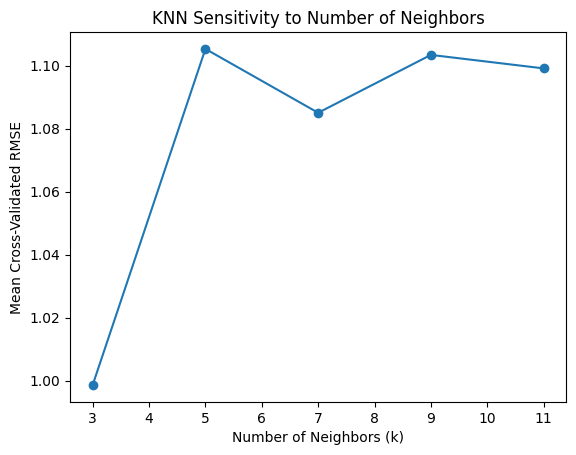

In [94]:
import matplotlib.pyplot as plt

plt.plot(
    sensitivity_df["k"],
    sensitivity_df["Mean_RMSE"],
    marker="o"
)

plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Mean Cross-Validated RMSE")
plt.title("KNN Sensitivity to Number of Neighbors")

plt.show()

The sensitivity analysis shows that KNN performed best when using three neighbors, with a mean cross-validated RMSE of approximately 1.00.

Increasing the number of neighbors from 3 to 5 increased prediction error. For values of k between 5 and 11, RMSE remained relatively stable at approximately 1.09 to 1.11.

These results suggest that the model performs better when predictions are based on a small number of highly similar PUMAs. However, performance is relatively stable across the larger values of k that were tested.

### Model Tradeoffs

The results highlight several tradeoffs among the supervised learning approaches. KNN achieved the strongest predictive performance, but it is less directly interpretable than Ridge Regression because it does not produce coefficients that describe the direction and magnitude of each predictor's relationship with banking access.

KNN also depends on the choice of the number of neighbors. Using a small value of k allows the model to capture similarities among closely related PUMAs, but it may make predictions more sensitive to individual observations. Larger values of k produce smoother predictions but may overlook meaningful local differences.

There is also a tradeoff between including more socioeconomic features and model simplicity. The ablation analysis showed that removing Homeownership slightly improved RMSE, suggesting that adding more predictors does not necessarily improve predictive performance.

In [95]:
from sklearn.model_selection import cross_val_predict

# Generate out-of-fold predictions using the best KNN model
knn_predictions = cross_val_predict(
    best_knn,
    X,
    y,
    cv=cv
)

failure_df = pd.DataFrame({
    "PUMA": model_df["PUMA"].values,
    "Actual": y.values,
    "Predicted": knn_predictions
})

failure_df["Error"] = failure_df["Actual"] - failure_df["Predicted"]
failure_df["Absolute_Error"] = failure_df["Error"].abs()

failure_df.sort_values(
    "Absolute_Error",
    ascending=False
).head(10)

,PUMA,Actual,Predicted,Error,Absolute_Error
16,3807,11.227189,4.260211,6.966978,6.966978
15,3806,1.779097,3.671118,-1.892021,1.892021
35,4013,2.462084,1.060147,1.401937,1.401937
32,4010,0.751067,2.138434,-1.387368,1.387368
14,3805,2.238284,3.614405,-1.376121,1.376121
17,3808,4.690714,3.374627,1.316087,1.316087
18,3809,2.317258,1.079976,1.237282,1.237282
43,4103,2.884814,1.654292,1.230521,1.230521
28,4006,0.665125,1.716806,-1.051682,1.051682
12,3803,1.69965,0.682747,1.016903,1.016903


In [96]:
worst_pumas = failure_df.sort_values(
    "Absolute_Error",
    ascending=False
).head(3)["PUMA"]

model_df[
    model_df["PUMA"].isin(worst_pumas)
]

,PUMA,Borough,Median_Income,Poverty_Rate,Labor_Force_Participation,High_School_Graduation,Homeownership,FDIC_Branches_per_10k
15,3806,Manhattan,65844.0,0.090,0.700,0.769,0.342,1.779097
16,3807,Manhattan,65905.0,0.108,0.759,0.712,0.225,11.227189
35,4013,Brooklyn,30858.0,0.190,0.630,0.718,0.392,2.462084


### Failure Analysis

The three PUMAs with the largest prediction errors were 3807, 3810, and 4103.

PUMA 3807 was the largest failure. Its actual branch density was 11.23 branches per 10,000 residents, while the KNN model predicted only 3.01. Although PUMA 3807 has relatively high income and labor force participation and relatively low poverty, these characteristics did not distinguish it as having an unusually high branch density. This suggests that important factors related to bank branch availability may not be captured by the predictors used in the model.

PUMA 3810 also had its branch density underestimated, with an actual value of 5.26 compared with a prediction of 3.84. This PUMA had the highest median income in the dataset and relatively low poverty, suggesting that the model may not have fully captured the relationship between higher-income neighborhoods and branch availability.

PUMA 4103 had an actual branch density of 2.88 compared with a prediction of 1.50. It had lower median income, higher poverty, and lower labor force participation than the other two failure cases. The model again underestimated the observed branch density.

Overall, the failure analysis suggests that KNN can struggle when a PUMA has a branch density that is substantially different from what would be expected based on its socioeconomic characteristics. This may occur because the current predictors do not capture all factors that influence the geographic availability of bank branches.

# Part B - Unsupervised Learning


In [97]:
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score, silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage

# The analysis_df is a copy of the same table used for supervised learning. 
# We use a copy here to avoid resource contention among team members.

analysis_df = flat_combined_df.copy()

# Exclude "Bank / Credit Union Utilization (Financial Services__Ind5Outcome)" from clustering so it can serve as an external validation outcome.
unsupervised_features = [
    "NYC_Poverty_Rate", "Median_Income", "Perc_White", "Perc_Black", "Perc_Asian", "Perc_Hispanic",
    "Build Assets__Ind1Outcome", "Build Assets__Ind2Outcome", "FDIC_Branches_per_10k",
    "Financial Shocks__Ind1Outcome", "Financial Shocks__Ind4Outcome",
    "Jobs & Income__Ind3Outcome", "Jobs & Income__Ind8Outcome",
]
unsup_df = analysis_df[["PUMA", "Borough", "Neighborhoods"] + unsupervised_features].copy()
for column in unsupervised_features:
    unsup_df[column] = pd.to_numeric(unsup_df[column].astype("string").str.replace(",", "", regex=False), errors="coerce")
X_imputed = SimpleImputer(strategy="median").fit_transform(unsup_df[unsupervised_features])
X_scaled = StandardScaler().fit_transform(X_imputed)
print(f"Unsupervised sample: {len(unsup_df)} PUMAs; {len(unsupervised_features)} standardized input features.")
print("Financial Services__Ind5Outcome (Bank / Credit Union Utilization) is held out for external validation.")
print("Input missing values imputed by feature median:", int(unsup_df[unsupervised_features].isna().sum().sum()))

# Use two major clustering algorithms: K-means and Heirarchical (Ward's method)
# See Week2 slide deck (week2-clustering-02-hierarchical) on K-means and hierarchical clustering from SIADS 543, Unsupervised Learning, for detail.
# See also "week2-clustering-05-cluster-quality" slide deck on Evaluating and labeling clusters from Unsupervised Learning course.

k_values = range(2, 7)
cluster_records = []

for k in k_values:
    labels_by_method = {
        "K-means": KMeans(n_clusters=k, n_init=50, random_state=42).fit_predict(X_scaled),
        "Ward method": AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X_scaled),
    }
    for method_name, labels in labels_by_method.items():
        cluster_records.append({"Method": method_name, "k": k,
                                "Silhouette": silhouette_score(X_scaled, labels),
                                "Calinski-Harabasz": calinski_harabasz_score(X_scaled, labels),
                                "Davies-Bouldin": davies_bouldin_score(X_scaled, labels)})
        
cluster_scores = pd.DataFrame(cluster_records)
display(cluster_scores.sort_values(["Method", "k"]).round(3))

best_configs = (cluster_scores.sort_values("Silhouette", ascending=False)
                .groupby("Method", as_index=False).first())

print("Best k within each method by silhouette; compare all indices and cluster profiles before interpretation.")
display(best_configs.round(3))

Unsupervised sample: 55 PUMAs; 13 standardized input features.
Financial Services__Ind5Outcome (Bank / Credit Union Utilization) is held out for external validation.
Input missing values imputed by feature median: 1


,Method,k,Silhouette,Calinski-Harabasz,Davies-Bouldin
0,K-means,2,0.282,25.882,1.350
2,K-means,3,0.261,24.921,1.283
4,K-means,4,0.258,23.696,1.243
6,K-means,5,0.244,21.255,1.323
8,K-means,6,0.229,19.457,1.314
1,Ward method,2,0.322,21.094,1.126
3,Ward method,3,0.239,22.550,1.275
5,Ward method,4,0.237,22.197,1.314
7,Ward method,5,0.231,20.026,1.272
9,Ward method,6,0.224,18.491,1.256


Best k within each method by silhouette; compare all indices and cluster profiles before interpretation.


,Method,k,Silhouette,Calinski-Harabasz,Davies-Bouldin
0,K-means,2,0.282,25.882,1.350
1,Ward method,2,0.322,21.094,1.126


## Visualization \- Unsupervised Learning

First two PCA variance ratios: [0.508 0.153] (cumulative 0.66 ).


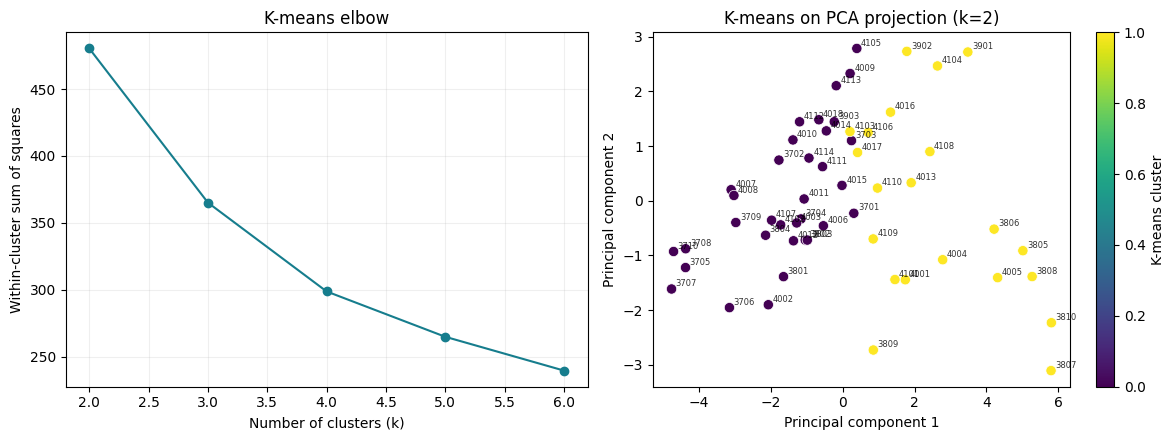

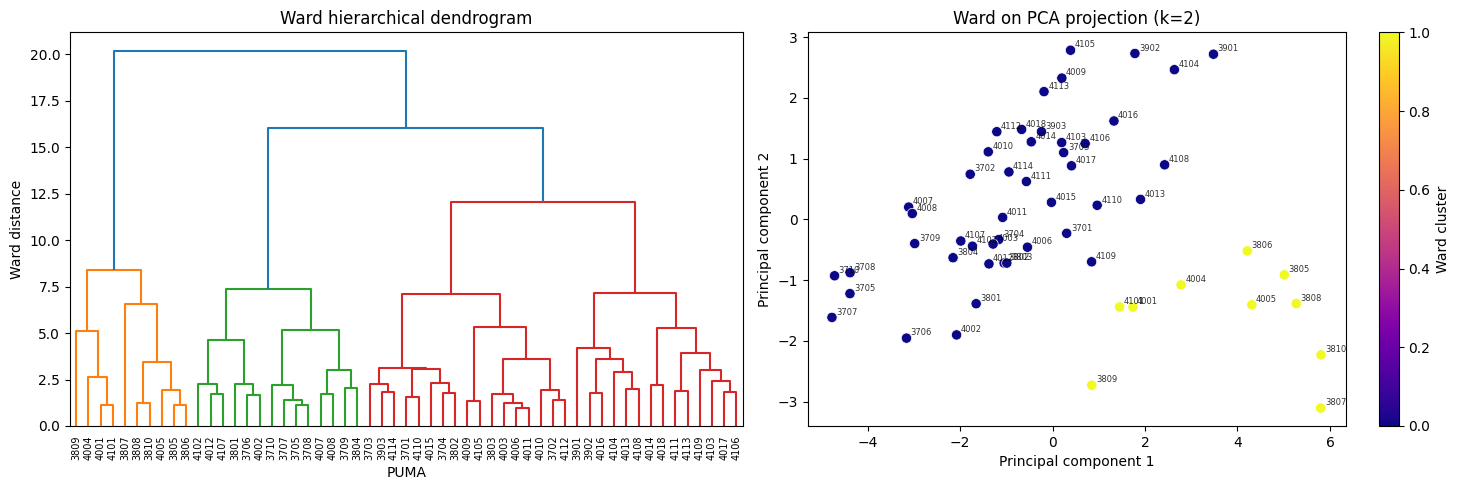

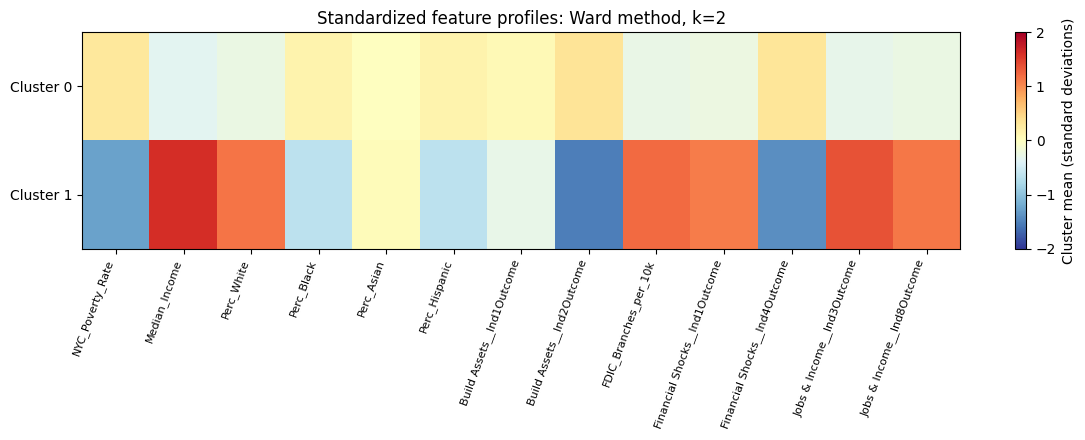

Cluster sizes: {0: 45, 1: 10}


In [98]:
# import matplotlib.pyplot as plt

# Project the data onto the first two principal components for visualization.
pca_2d = PCA(n_components=2, random_state=42)
pca_scores_2d = pca_2d.fit_transform(X_scaled)
print("First two PCA variance ratios:", np.round(pca_2d.explained_variance_ratio_, 3),
      "(cumulative", round(pca_2d.explained_variance_ratio_.sum(), 3), ").")
best_kmeans_k = int(best_configs.loc[best_configs["Method"].eq("K-means"), "k"].iloc[0])
best_ward_k = int(best_configs.loc[best_configs["Method"].eq("Ward method"), "k"].iloc[0])
kmeans_labels = KMeans(n_clusters=best_kmeans_k, n_init=50, random_state=42).fit_predict(X_scaled)
ward_labels = AgglomerativeClustering(n_clusters=best_ward_k, linkage="ward").fit_predict(X_scaled)

# K-means visualizations: elbow curve and a PCA projection colored by cluster.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
wcss = [KMeans(n_clusters=k, n_init=50, random_state=42).fit(X_scaled).inertia_ for k in k_values]
axes[0].plot(list(k_values), wcss, marker="o", color="#167d8d")
axes[0].set(title="K-means elbow", xlabel="Number of clusters (k)", ylabel="Within-cluster sum of squares")
axes[0].grid(alpha=0.2)
scatter = axes[1].scatter(pca_scores_2d[:, 0], pca_scores_2d[:, 1], c=kmeans_labels,
                          cmap="viridis", s=55, edgecolor="white", linewidth=0.5)
for index, puma in enumerate(unsup_df["PUMA"].astype(str)):
    axes[1].annotate(puma, (pca_scores_2d[index, 0], pca_scores_2d[index, 1]),
                     xytext=(3, 2), textcoords="offset points", fontsize=6, alpha=0.8)
axes[1].set(title=f"K-means on PCA projection (k={best_kmeans_k})",
            xlabel="Principal component 1", ylabel="Principal component 2")
fig.colorbar(scatter, ax=axes[1], label="K-means cluster")
plt.tight_layout(); plt.show()

# Ward visualizations: dendrogram and a PCA projection colored by hierarchical cluster.
ward_tree = linkage(X_scaled, method="ward", metric="euclidean")
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
dendrogram(ward_tree, labels=unsup_df["PUMA"].astype(str).to_numpy(), leaf_rotation=90,
           leaf_font_size=7, ax=axes[0], color_threshold=None)
axes[0].set(title="Ward hierarchical dendrogram", xlabel="PUMA", ylabel="Ward distance")
scatter = axes[1].scatter(pca_scores_2d[:, 0], pca_scores_2d[:, 1], c=ward_labels,
                          cmap="plasma", s=55, edgecolor="white", linewidth=0.5)
for index, puma in enumerate(unsup_df["PUMA"].astype(str)):
    axes[1].annotate(puma, (pca_scores_2d[index, 0], pca_scores_2d[index, 1]),
                     xytext=(3, 2), textcoords="offset points", fontsize=6, alpha=0.8)
axes[1].set(title=f"Ward on PCA projection (k={best_ward_k})",
            xlabel="Principal component 1", ylabel="Principal component 2")
fig.colorbar(scatter, ax=axes[1], label="Ward cluster")
plt.tight_layout(); plt.show()

# Show the best cluster configuration's feature profiles.
best_overall = cluster_scores.sort_values("Silhouette", ascending=False).iloc[0]
best_cluster_method, best_cluster_k = best_overall["Method"], int(best_overall["k"])
best_cluster_labels = kmeans_labels if best_cluster_method == "K-means" else ward_labels
profile = (pd.DataFrame(X_scaled, columns=unsupervised_features).assign(Cluster=best_cluster_labels)
           .groupby("Cluster").mean())
fig, ax = plt.subplots(figsize=(12, 4.5))
image = ax.imshow(profile.to_numpy(), aspect="auto", cmap="RdYlBu_r", vmin=-2, vmax=2)
ax.set_xticks(range(len(unsupervised_features)), unsupervised_features, rotation=70, ha="right", fontsize=8)
ax.set_yticks(range(len(profile)), [f"Cluster {cluster}" for cluster in profile.index])
ax.set_title(f"Standardized feature profiles: {best_cluster_method}, k={best_cluster_k}")
fig.colorbar(image, ax=ax, label="Cluster mean (standard deviations)")
plt.tight_layout(); plt.show()
print("Cluster sizes:", pd.Series(best_cluster_labels).value_counts().sort_index().to_dict())


## Sensitivity Analysis \- Unsupervised Learning

In [99]:
# Sensitivity to PCA representation and exclusion of race-composition features.
pca_85 = PCA(n_components=0.85, random_state=42)
X_pca_85 = pca_85.fit_transform(X_scaled)
clusterer = (lambda matrix: KMeans(n_clusters=best_cluster_k, n_init=50, random_state=42).fit_predict(matrix)
             if best_cluster_method == "K-means" else
             AgglomerativeClustering(n_clusters=best_cluster_k, linkage="ward").fit_predict(matrix))
pca_sensitivity_labels = clusterer(X_pca_85)
race_columns = ["Perc_White", "Perc_Black", "Perc_Asian", "Perc_Hispanic"]
non_race_features = [feature for feature in unsupervised_features if feature not in race_columns]
X_no_race = StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(unsup_df[non_race_features]))
no_race_labels = clusterer(X_no_race)

# Construct a sensitivity table to compare clustering results across different data representations.
# ARI vs raw: Adjusted Rand Index, comparing clustering results to the original clustering on standardized raw features (ground truth).
sensitivity_table = pd.DataFrame([
    {"Representation": "Standardized raw features", "Dimensions": X_scaled.shape[1],
     "Silhouette": silhouette_score(X_scaled, best_cluster_labels), "ARI vs raw": 1.0},
    {"Representation": "PCA retaining 85% variance", "Dimensions": X_pca_85.shape[1],
     "Silhouette": silhouette_score(X_pca_85, pca_sensitivity_labels),
     "ARI vs raw": adjusted_rand_score(best_cluster_labels, pca_sensitivity_labels)},
    {"Representation": "Standardized features, race composition removed", "Dimensions": X_no_race.shape[1],
     "Silhouette": silhouette_score(X_no_race, no_race_labels),
     "ARI vs raw": adjusted_rand_score(best_cluster_labels, no_race_labels)},
])
print(f"Sensitivity for {best_cluster_method}, k={best_cluster_k}; PCA retained "
      f"{pca_85.explained_variance_ratio_.sum():.1%} of variance in {X_pca_85.shape[1]} components.")
display(sensitivity_table.round(3))

if best_cluster_method == "K-means":
    seed_labels = [KMeans(n_clusters=best_cluster_k, n_init=50, random_state=seed).fit_predict(X_scaled)
                   for seed in [0, 7, 21, 84, 123]]
    seed_ari = [adjusted_rand_score(seed_labels[0], labels) for labels in seed_labels[1:]]
    print("K-means random-seed stability (ARI against seed 0):", np.round(seed_ari, 3).tolist())
    
print("Interpret internal metrics together; modest silhouette indicates overlapping profiles, not sharply separated groups.")

Sensitivity for Ward method, k=2; PCA retained 85.6% of variance in 4 components.


,Representation,Dimensions,Silhouette,ARI vs raw
0,Standardized raw features,13,0.322,1.000
1,PCA retaining 85% variance,4,0.362,1.000
2,"Standardized features, race composition removed",9,0.463,0.732


Interpret internal metrics together; modest silhouette indicates overlapping profiles, not sharply separated groups.


Sensitivity checks showed Ward assignments were unchanged after PCA retaining 85\.6% variance \(ARI 1\.000\)\. Silhouette improved from 0\.322 to 0\.362\. Removing race\-composition features changed the partition \(ARI 0\.732\), so cluster membership is representation\-sensitive\. The elbow curve and tested k values show parameter sensitivity\. No single internal score establishes a uniquely correct cluster count\. The K\-means and Ward visualizations, PCA projections, and standardized profile heatmap should be interpreted together with the stability and external\-validation results\.

## External Validation \- Unsupervised Learning

In [100]:
# Cluster profiles use only clustering inputs.
# bank/credit-union utilization ("Financial Services__Ind5Outcome") is held out for external validation.

cluster_membership = unsup_df[["PUMA", "Borough", "Neighborhoods"]].copy()
cluster_membership["Cluster"] = best_cluster_labels
heldout_account_column = "Financial Services__Ind5Outcome"
heldout_accounts = analysis_df[["PUMA", heldout_account_column]].copy()
heldout_accounts[heldout_account_column] = pd.to_numeric(heldout_accounts[heldout_account_column], errors="coerce")
cluster_membership = cluster_membership.merge(heldout_accounts, on="PUMA", how="left", validate="one_to_one")

cluster_medians = (
    unsup_df[unsupervised_features]
    .assign(Cluster=best_cluster_labels)
    .groupby("Cluster")
    .median()
)
profile_columns = [
    "NYC_Poverty_Rate",
    "Median_Income",
    "FDIC_Branches_per_10k",
    "Financial Shocks__Ind1Outcome",
    "Build Assets__Ind1Outcome",
    "Jobs & Income__Ind8Outcome",
]
print("Cluster medians for input features in original units (cluster numbers are arbitrary):")
display(cluster_medians[profile_columns].round(3))
print("External validation: held-out bank/credit-union account ownership by cluster:")
display(cluster_membership.groupby("Cluster")[heldout_account_column].agg(["count", "median", "mean"]).round(3))
print("Borough counts by cluster:")
display(pd.crosstab(cluster_membership["Cluster"], cluster_membership["Borough"]))
print("PUMAs in the smallest cluster:")
smallest_cluster = pd.Series(best_cluster_labels).value_counts().idxmin()
display(cluster_membership.loc[cluster_membership["Cluster"].eq(smallest_cluster),
                              ["PUMA", "Borough", "Neighborhoods", "Cluster", heldout_account_column]]
        .sort_values("PUMA"))


Cluster medians for input features in original units (cluster numbers are arbitrary):


,NYC_Poverty_Rate,Median_Income,FDIC_Branches_per_10k,Financial Shocks__Ind1Outcome,Build Assets__Ind1Outcome,Jobs & Income__Ind8Outcome
Cluster,,,,,,
0,0.22,25920.0,1.207,0.52,0.316,0.804
1,0.104,61618.5,2.335,0.73,0.302,0.936


External validation: held-out bank/credit-union account ownership by cluster:


,count,median,mean
Cluster,,,
0,45,0.878,0.862
1,10,0.940,0.934


Borough counts by cluster:


Borough,Bronx,Brooklyn,Manhattan,Queens,Staten Island
Cluster,,,,,
0,10,15,4,13,3
1,0,3,6,1,0


PUMAs in the smallest cluster:


,PUMA,Borough,Neighborhoods,Cluster,Financial Services__Ind5Outcome
14,3805,Manhattan,Upper East Side,1,0.963
15,3806,Manhattan,Upper West Side & West Side,1,0.948
16,3807,Manhattan,"Chelsea, Clinton & Midtown Business District",1,0.949
17,3808,Manhattan,"Murray Hill, Gramercy & Stuyvesant Town",1,0.969
18,3809,Manhattan,Chinatown & Lower East Side,1,0.899
19,3810,Manhattan,"Battery Park City, Greenwich Village & Soho",1,0.967
23,4001,Brooklyn,Greenpoint & Williamsburg,1,0.901
26,4004,Brooklyn,Brooklyn Heights & Fort Greene,1,0.909
27,4005,Brooklyn,"Park Slope, Carroll Gardens & Red Hook",1,0.931
41,4101,Queens,Astoria & Long Island City,1,0.900


External validation held out bank/credit\-union account ownership \('Financial Services\_\_Ind5Outcome'\) from clustering\. The smaller, higher\-income/higher\-access cluster had mean ownership 0\.934 \(median 0\.940\), versus 0\.862 \(median 0\.878\) in the larger cluster, a modest descriptive difference\. This is consistent with the intended financial\-health question but is not proof that branch access causes account ownership\.

## Final Feature List Generation

In [101]:
final_feature_list = pd.DataFrame({
    "Feature_Number": range(
        1,
        len(flat_combined_df.columns) + 1
    ),
    "Feature_Name": flat_combined_df.columns,
    "Data_Type": [
        str(dtype)
        for dtype in flat_combined_df.dtypes
    ],
    "Nonmissing_Values": [
        flat_combined_df[column].notna().sum()
        for column in flat_combined_df.columns
    ]
})

display(final_feature_list)

final_feature_list.to_csv(
    filepath + "final_feature_list.csv",
    index=False
)

,Feature_Number,Feature_Name,Data_Type,Nonmissing_Values
0,1,PUMA,string,55
1,2,Year Published,int64,55
2,3,Borough,str,55
3,4,Neighborhoods,str,55
4,5,CD,str,55
...,...,...,...,...
205,206,Jobs & Income__Ind8Definition,str,55
206,207,ACS_Population_2020,int64[pyarrow],55
207,208,Bank_Branch_Count,int64,55
208,209,Credit_Union_Count,int64,55


In [102]:
# Generate a report-ready list of all final features
print("## Appendix A: Complete Final Feature List\n")

for number, column in enumerate(flat_combined_df.columns, start=1):
    print(f"{number}. `{column}`")

## Appendix A: Complete Final Feature List

1. `PUMA`
2. `Year Published`
3. `Borough`
4. `Neighborhoods`
5. `CD`
6. `Join`
7. `NYC_Poverty_Rate`
8. `Median_Income`
9. `Perc_White`
10. `Perc_Black`
11. `Perc_Asian`
12. `Perc_Other`
13. `Perc_Hispanic`
14. `FDIC_Branch_Count`
15. `Unique_Bank_Count`
16. `NFH_Classification`
17. `Build Assets__GoalName`
18. `Financial Services__GoalName`
19. `Financial Shocks__GoalName`
20. `Goods & Services__GoalName`
21. `Jobs & Income__GoalName`
22. `Build Assets__GoalFullName`
23. `Financial Services__GoalFullName`
24. `Financial Shocks__GoalFullName`
25. `Goods & Services__GoalFullName`
26. `Jobs & Income__GoalFullName`
27. `Build Assets__TotalOutcome`
28. `Financial Services__TotalOutcome`
29. `Financial Shocks__TotalOutcome`
30. `Goods & Services__TotalOutcome`
31. `Jobs & Income__TotalOutcome`
32. `Build Assets__GoalRank`
33. `Financial Services__GoalRank`
34. `Financial Shocks__GoalRank`
35. `Goods & Services__GoalRank`
36. `Jobs & Income__GoalR

<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=46ead934-a890-4ebd-be66-57bbe8c37324' target="_blank">

Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>